## Домашнее задание. Вдовина Д.Н.
## Построение прототипа книжного рекомендательного сервиса


**Запуск:** требуется Python-окружение с `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `scipy`, `scikit-surprise` и CSV-файлами `ratings.csv`, `books.csv`, `tags.csv`, `book_tags.csv` из Goodbooks-10k. По умолчанию CSV читаются из `../data/` относительно текущего рабочего каталога (см. следующую ячейку); путь можно изменить. Все этапы необходимо выполнять последовательно сверху вниз.

In [1]:
# Импорт необходимых библиотек

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize

from pathlib import Path

In [2]:
# Каталог Goodbooks-10k (при необходимости измените путь)
DATA_DIRECTORY = Path("../data")
required_files = ["ratings.csv", "books.csv", "tags.csv", "book_tags.csv"]
missing_files = [name for name in required_files if not (DATA_DIRECTORY / name).is_file()]
if missing_files:
    raise FileNotFoundError(
        f"Не найдены CSV-файлы в {DATA_DIRECTORY.resolve()}: {', '.join(missing_files)}. "
        "Укажите правильный путь в DATA_DIRECTORY."
    )

ratings = pd.read_csv(DATA_DIRECTORY / "ratings.csv")
books = pd.read_csv(DATA_DIRECTORY / "books.csv")
tags = pd.read_csv(DATA_DIRECTORY / "tags.csv")
book_tags = pd.read_csv(DATA_DIRECTORY / "book_tags.csv")

# Проверка и предобработка загруженных данных

Первичный разведочный анализ проводится на полном наборе данных для изучения его статистических характеристик. При обучении и настройке рекомендательных моделей используются исключительно обучающая и валидационная выборки. Тестовые взаимодействия не участвуют в выборе моделей и применяются только для итоговой оценки.

In [3]:
# Изучение размеров датафреймов (признаки и количество записей)
print("Оценки:", ratings.shape)
print("Книги:", books.shape)
print("Теги:", tags.shape)
print("Book Теги:", book_tags.shape)

Оценки: (5976479, 3)
Книги: (10000, 23)
Теги: (34252, 2)
Book Теги: (999912, 3)


In [4]:
# Вывод первых 5 строк каждого датафрейма для ознакомления с данными
print("Оценки:"), display(ratings.head(5))
print("Книги:"), display(books.head(5))
print("Теги:"), display(tags.head(5))
print("Book Теги:"), display(book_tags.head(5))


Оценки:


,user_id,book_id,rating
0,1,258,5
1,2,4081,4
2,2,260,5
3,2,9296,5
4,2,2318,3


Книги:


,book_id,goodreads_book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,...,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,...,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...


Теги:


,tag_id,tag_name
0,0,-
1,1,--1-
2,2,--10-
3,3,--12-
4,4,--122-


Book Теги:


,goodreads_book_id,tag_id,count
0,1,30574,167697
1,1,11305,37174
2,1,11557,34173
3,1,8717,12986
4,1,33114,12716


(None, None)

In [5]:
# Проверка структуры и типов данных
print("Оценки:")
ratings.info()
print("\nКниги:")
books.info()
print("\nТеги:")
tags.info()
print("\nТеги книг:")
book_tags.info()

Оценки:
<class 'pandas.DataFrame'>
RangeIndex: 5976479 entries, 0 to 5976478
Data columns (total 3 columns):
 #   Column   Dtype
---  ------   -----
 0   user_id  int64
 1   book_id  int64
 2   rating   int64
dtypes: int64(3)
memory usage: 136.8 MB

Книги:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   book_id                    10000 non-null  int64  
 1   goodreads_book_id          10000 non-null  int64  
 2   best_book_id               10000 non-null  int64  
 3   work_id                    10000 non-null  int64  
 4   books_count                10000 non-null  int64  
 5   isbn                       9300 non-null   str    
 6   isbn13                     9415 non-null   float64
 7   authors                    10000 non-null  str    
 8   original_publication_year  9979 non-null   float64
 9   original_title           

In [6]:
# Проверка наличия пропущенных значений
print("Пропуски в оценках:"), display(ratings.isnull().sum())
print("Пропуски в книгах:"), display(books.isnull().sum())
print("Пропуски в тегах:"), display(tags.isnull().sum())
print("Book Пропуски в тегах:"), display(book_tags.isnull().sum())


Пропуски в оценках:


user_id    0
book_id    0
rating     0
dtype: int64

Пропуски в книгах:


book_id                         0
goodreads_book_id               0
best_book_id                    0
work_id                         0
books_count                     0
isbn                          700
isbn13                        585
authors                         0
original_publication_year      21
original_title                585
title                           0
language_code                1084
average_rating                  0
ratings_count                   0
work_ratings_count              0
work_text_reviews_count         0
ratings_1                       0
ratings_2                       0
ratings_3                       0
ratings_4                       0
ratings_5                       0
image_url                       0
small_image_url                 0
dtype: int64

Пропуски в тегах:


tag_id      0
tag_name    0
dtype: int64

Book Пропуски в тегах:


goodreads_book_id    0
tag_id               0
count                0
dtype: int64

(None, None)

In [7]:
# Проверка распределения значений (какие значения встречаются чаще всего)
print("Частоты значений оценок:"), display(ratings.value_counts())
print("Частоты значений в книгах:"), display(books.value_counts())
print("Частоты значений в тегах:"), display(tags.value_counts())
print("Book Частоты значений в тегах:"), display(book_tags.value_counts())

Частоты значений оценок:


user_id  book_id  rating
1        258      5         1
2        4081     4         1
         260      5         1
         9296     5         1
         2318     3         1
                           ..
49925    510      5         1
         528      4         1
         722      4         1
         949      5         1
         1023     4         1
Name: count, Length: 5976479, dtype: int64

Частоты значений в книгах:


book_id  goodreads_book_id  best_book_id  work_id   books_count  isbn        isbn13        authors                      original_publication_year  original_title                                                                             title                                                                                      language_code  average_rating  ratings_count  work_ratings_count  work_text_reviews_count  ratings_1  ratings_2  ratings_3  ratings_4  ratings_5  image_url                                                                                 small_image_url                                                                       
1        2767052            2767052       2792775   272          439023483   9.780439e+12  Suzanne Collins              2008.0                     The Hunger Games                                                                           The Hunger Games (The Hunger Games, #1)                                                    eng            4.34

Частоты значений в тегах:


tag_id  tag_name  
0       -             1
1       --1-          1
2       --10-         1
3       --12-         1
4       --122-        1
                     ..
34247   Ｃhildrens     1
34248   Ｆａｖｏｒｉｔｅｓ     1
34249   Ｍａｎｇａ         1
34250   ＳＥＲＩＥＳ        1
34251   ｆａｖｏｕｒｉｔｅｓ    1
Name: count, Length: 34252, dtype: int64

Book Частоты значений в тегах:


goodreads_book_id  tag_id  count
22369              25148   4        2
52629              10094   1        2
                   2928    1        2
                   13272   1        2
                   13322   1        2
                                   ..
33288638           21303   7        1
                   17271   7        1
                   1126    7        1
                   11478   7        1
                   27939   7        1
Name: count, Length: 999906, dtype: int64

(None, None)

In [8]:
# Проверка полных дубликатов строк
print("Оценки:", ratings.duplicated().sum())
print("Книги:", books.duplicated().sum())
print("Теги:", tags.duplicated().sum())
print("Теги книг:", book_tags.duplicated().sum())

Оценки: 0
Книги: 0
Теги: 0
Теги книг: 6


In [9]:
# Проверка повторных оценок одной книги одним пользователем
print(
    "Повторные пары пользователь–книга:",
    ratings.duplicated(subset=["user_id", "book_id"]).sum()
)

Повторные пары пользователь–книга: 0


In [10]:
# Удаление полных дубликатов
book_tags = book_tags.drop_duplicates().reset_index(drop=True)

print("Количество записей о тегах книг после очистки:", book_tags.shape)

Количество записей о тегах книг после очистки: (999906, 3)


### Промежуточный вывод по первичному анализу данных 

- Датасет содержит 10 000 книг, 5 976 479 пользовательских оценок, 34 252 тега и 999 906 записей о связях книг с тегами
- В таблицах ratings, tags и book_tags пропуски отсутствуют. В books обнаружены пропуски в пяти столбцах: isbn, isbn13, original_publication_year, original_title и language_code. Пропуски планируется заполнить, в удалении нет необходимости
- В таблице book_tags обнаружено и удалено 6 полных дубликатов строк. В остальных таблицах полные дубликаты отсутствуют. Дополнительно проверена уникальность пар user_id–book_id: повторных взаимодействий одной книги одним пользователем не выявлено.

In [11]:
# Анализ распределения оценок
# Основные статистические показатели
ratings_stats = ratings["rating"].describe()
display(ratings_stats.round(2).to_frame("Value"))

,Value
count,5976479.00
mean,3.92
std,0.99
min,1.00
25%,3.00
50%,4.00
75%,5.00
max,5.00


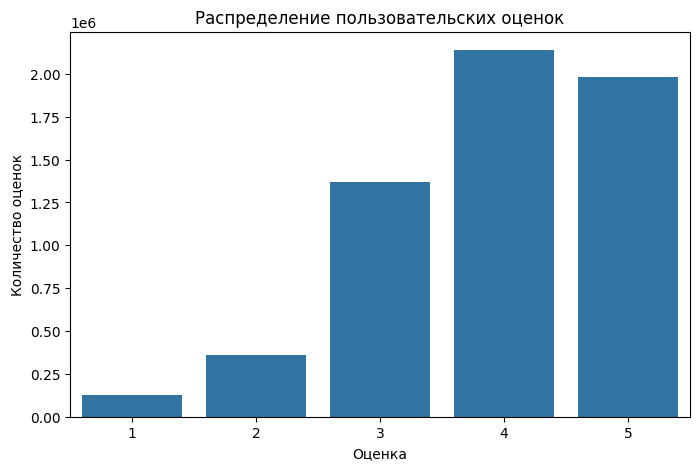

In [12]:
# Строим столбчатую диаграмму распределения оценок
plt.figure(figsize=(8, 5))
sns.countplot(data=ratings, x="rating")
plt.title("Распределение пользовательских оценок")
plt.xlabel("Оценка")
plt.ylabel("Количество оценок")
plt.show()

In [13]:
# Доля положительных оценок (4 и 5) и отрицательных (1 и 2)
positive_share = (ratings["rating"] >= 4).mean() * 100
print(f"Положительные оценки (4–5): {positive_share:.2f}%")
negative_share = (ratings["rating"] <= 2).mean() * 100
print(f"Отрицательные оценки (1–2): {negative_share:.2f}%")

Положительные оценки (4–5): 68.97%
Отрицательные оценки (1–2): 8.09%


## Промежуточный вывод

В наборе данных содержится 5 976 479 пользовательских оценок со средним значением 3,92 и медианой 4.
Распределение смещено в сторону высоких оценок: 68,97% составляют оценки 4–5, 22,94% — оценки 3 и только 8,09% — оценки 1–2.
Преобладание положительных оценок может влиять на обучение рекомендательных моделей и приводить к смещению прогнозов в сторону высоких значений.

Поэтому при оценке качества необходимо учитывать не только точность прогнозирования оценок (RMSE), но и способность моделей рекомендовать релевантные книги, используя Precision@10, Recall@10 и nDCG@10.

In [14]:
# Произведем подсчет количества оценок каждого пользователя и книги, чтобы понять распределение активности пользователей и популярности книг
  
user_rating_counts = ratings.groupby('user_id')['rating'].count()
print("Количество оценок по пользователям:\n", user_rating_counts.describe())


Количество оценок по пользователям:
 count    53424.000000
mean       111.868804
std         26.071224
min         19.000000
25%         96.000000
50%        111.000000
75%        128.000000
max        200.000000
Name: rating, dtype: float64


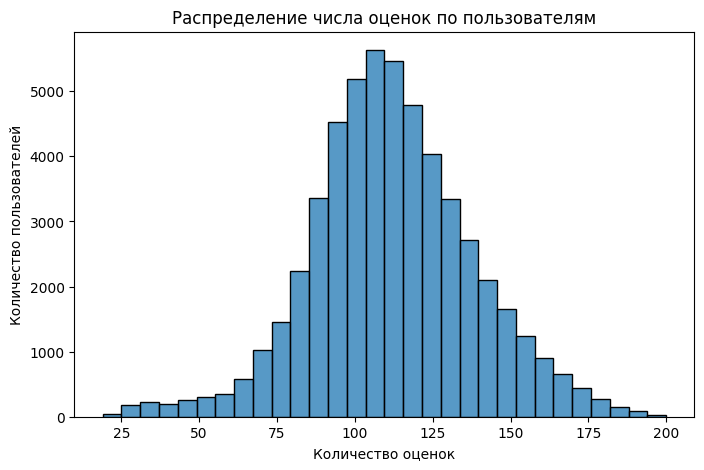

In [15]:
# Строим графики распределения количества оценок на пользователя
plt.figure(figsize=(8, 5))
sns.histplot(user_rating_counts, bins=30, kde=False)
plt.title("Распределение числа оценок по пользователям")
plt.xlabel("Количество оценок")
plt.ylabel("Количество пользователей")
plt.show()

In [16]:
# Определим долю пользователей с высокой и низкой активностью (например, более 150 оценок и менее 50 оценок)
high_activity_users = (user_rating_counts > 150).mean() * 100
low_activity_users = (user_rating_counts < 50).mean() * 100
print(f"Пользователи с высокой активностью (>150 оценок): {high_activity_users:.2f}%")
print(f"Пользователи с низкой активностью (<50 оценок): {low_activity_users:.2f}%")

Пользователи с высокой активностью (>150 оценок): 7.51%
Пользователи с низкой активностью (<50 оценок): 1.68%


### Промежуточный вывод

В датасете представлены 53 424 пользователя, каждый из которых оценил от 19 до 200 книг. Медианное количество оценок составляет 111. Основная масса пользователей сосредоточена в диапазоне примерно 90–130 оценок.

Доля пользователей с высокой активностью (более 150 оценок) составляет 7,51%, а с низкой активностью (менее 50 оценок) — 1,68%. Следовательно, в датасете преобладают пользователи с достаточно большой историей взаимодействий.

Пользователей без истории оценок в данных нет, поэтому классический сценарий холодного старта новых пользователей невозможно непосредственно исследовать на исходной выборке. При этом после разделения данных на обучающую, валидационную и тестовую выборки количество доступных модели оценок каждого пользователя уменьшится, что необходимо учитывать при формировании персонализированных рекомендаций.

In [17]:
# Основные показатели популярности книг
book_rating_counts = ratings.groupby('book_id')['rating'].count()
print("Количество оценок по книгам:\n", book_rating_counts.describe())

Количество оценок по книгам:
 count    10000.000000
mean       597.647900
std       1267.289788
min          8.000000
25%        155.000000
50%        248.000000
75%        503.000000
max      22806.000000
Name: rating, dtype: float64


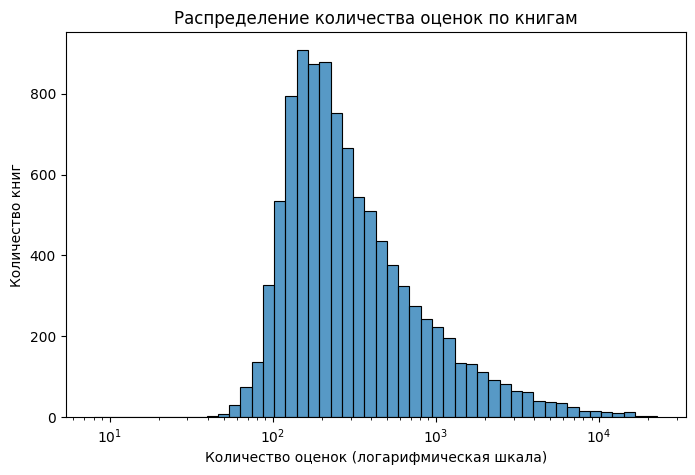

In [18]:
# Строим распределение количества оценок книг в логарифмической шкале

plt.figure(figsize=(8, 5))

sns.histplot(book_rating_counts, bins=50, log_scale=True)

plt.title("Распределение количества оценок по книгам")
plt.xlabel("Количество оценок (логарифмическая шкала)")
plt.ylabel("Количество книг")

plt.show()

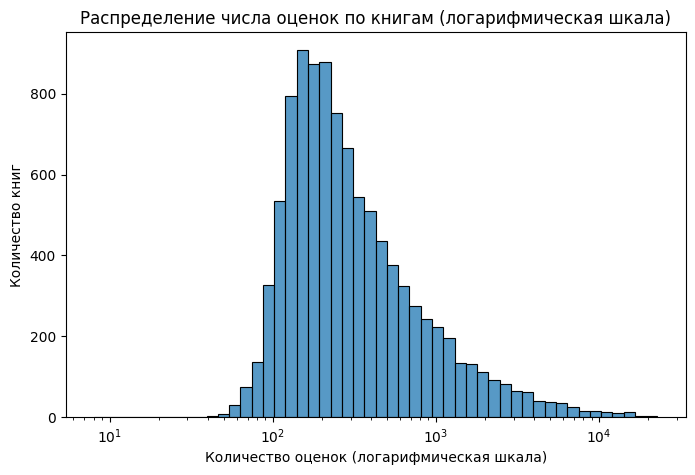

In [19]:
# Построим график распределения популярности книг в логарифмическом масштабе
plt.figure(figsize=(8, 5))

sns.histplot(book_rating_counts, bins=50, log_scale=True)

plt.title("Распределение числа оценок по книгам (логарифмическая шкала)")
plt.xlabel("Количество оценок (логарифмическая шкала)")
plt.ylabel("Количество книг")

plt.show()

In [20]:
# Выведем ТОП-10 самых популярных книг по количеству оценок
top_books = book_rating_counts.sort_values(ascending=False).head(10)
top_books_info = books[books['book_id'].isin(top_books.index)][['book_id', 'title', 'authors']]
top_books_info = top_books_info.set_index('book_id').loc[top_books.index]
top_books_info['rating_count'] = top_books.values
display(top_books_info)

,title,authors,rating_count
book_id,,,
1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,22806
2,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",21850
4,To Kill a Mockingbird,Harper Lee,19088
3,"Twilight (Twilight, #1)",Stephenie Meyer,16931
5,The Great Gatsby,F. Scott Fitzgerald,16604
17,"Catching Fire (The Hunger Games, #2)",Suzanne Collins,16549
20,"Mockingjay (The Hunger Games, #3)",Suzanne Collins,15953
18,Harry Potter and the Prisoner of Azkaban (Harr...,"J.K. Rowling, Mary GrandPré, Rufus Beck",15855
23,Harry Potter and the Chamber of Secrets (Harry...,"J.K. Rowling, Mary GrandPré",15657


In [21]:
# Рассчитаем концентрацию популярности книг. 
# Доля оценок, приходящихся на топ-10% самых популярных книг
top_10_percent = book_rating_counts.nlargest(1000)
popularity_share = top_10_percent.sum() / book_rating_counts.sum() * 100
print(f"Доля оценок у 10% самых популярных книг: {popularity_share:.2f}%")

Доля оценок у 10% самых популярных книг: 53.20%


### Промежуточный вывод

Популярность книг распределена неравномерно: среднее количество оценок на книгу составляет около 598, а медианное — 248. На 10% самых популярных книг приходится 53,20% всех пользовательских оценок. Распределение имеет выраженный длинный правый хвост: большинство книг получает относительно небольшое количество оценок, тогда как отдельные книги — значительно больше.

Такая концентрация взаимодействий создаёт предпосылки для *Popularity Bias*: рекомендательные модели могут отдавать предпочтение популярным книгам, поскольку для них доступно больше пользовательских оценок. При дальнейшем сравнении моделей важно учитывать этот риск.

In [22]:
# Анализ наиболее распространенных тегов, связанных с книгами
# Объединим таблицы book_tags и tags для получения информации о тегах
book_tags_with_names = book_tags.merge(tags, on='tag_id', how='left')
display(book_tags_with_names.head(5))

,goodreads_book_id,tag_id,count,tag_name
0,1,30574,167697,to-read
1,1,11305,37174,fantasy
2,1,11557,34173,favorites
3,1,8717,12986,currently-reading
4,1,33114,12716,young-adult


In [23]:
# Проверка объединения таблиц
print("Строк до объединения:", len(book_tags))
print("Строк после объединения:", len(book_tags_with_names))
print("Отсутствующие названия тегов:", book_tags_with_names["tag_name"].isnull().sum())

Строк до объединения: 999906
Строк после объединения: 999906
Отсутствующие названия тегов: 0


In [24]:
# ТОП-20 тегов по суммарному количеству использований
top_tags = (
    book_tags_with_names.groupby("tag_name")["count"]
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

display(top_tags) 

tag_name
to-read               140718761
currently-reading       7507958
favorites               4503173
fiction                 3688819
fantasy                 3548157
young-adult             1848306
classics                1756920
books-i-own             1317235
romance                 1231926
owned                   1224279
ya                       898334
mystery                  872282
non-fiction              857901
historical-fiction       815421
series                   782637
science-fiction          703866
sci-fi                   597325
paranormal               542559
kindle                   506882
contemporary             486001
Name: count, dtype: int64

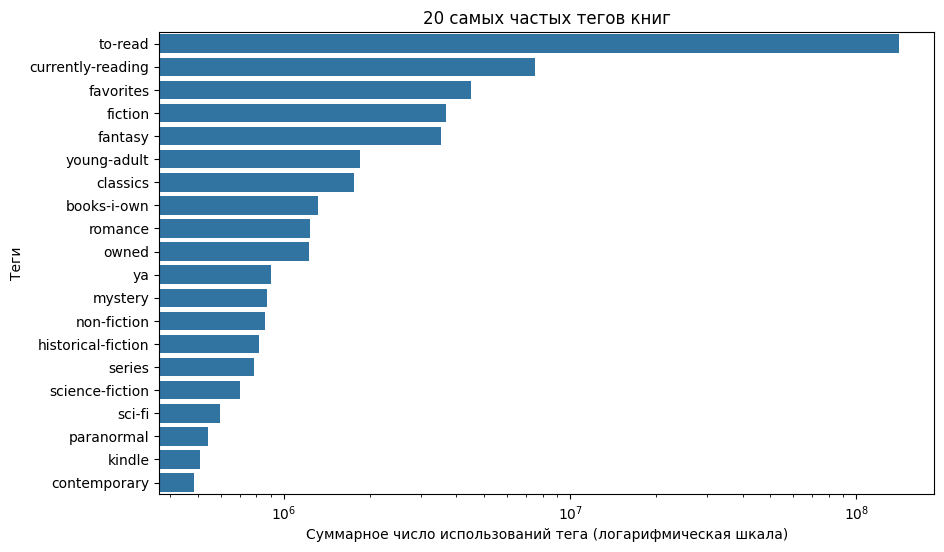

In [25]:
# Строим график распределения самых популярных тегов
plt.figure(figsize=(10, 6))
sns.barplot(x=top_tags.values, y=top_tags.index)
plt.xscale("log")
plt.title("20 самых частых тегов книг")
plt.xlabel("Суммарное число использований тега (логарифмическая шкала)")
plt.ylabel("Теги")
plt.show()

### Промежуточный вывод

Анализ показал, что наиболее распространёнными являются теги, связанные с пользовательской активностью: `to-read`, `currently-reading` и `favorites`. Особенно выделяется `to-read` — тег, обозначающий добавление книги в список планируемого чтения. Его суммарная частота значительно превышает частоты остальных тегов.

Среди популярных тегов также присутствуют содержательные характеристики книг: `fiction`, `fantasy`, `romance`, `mystery` и другие.

При построении Content-Based модели целесообразно исключить очевидные служебные теги, поскольку они не описывают тематику произведений и могут искажать оценку сходства книг. Тематические теги, напротив, могут использоваться для формирования их текстовых профилей.

In [26]:
# Рассчитаем разреженность матрицы взаимодействий

n_users = ratings["user_id"].nunique()
n_books = ratings["book_id"].nunique()
n_ratings = len(ratings)
sparsity = 1 - n_ratings / (n_users * n_books)

print(f"Пользователей: {n_users}")
print(f"Книги: {n_books}")
print(f"Оценки: {n_ratings}")
print(f"Разреженность: {sparsity:.2%}")

Пользователей: 53424
Книги: 10000
Оценки: 5976479
Разреженность: 98.88%


## Итоговый вывод EDA

В результате разведочного анализа датасета Goodbooks-10k выявлены следующие особенности:

1. **Преобладание положительных оценок.** Оценки 4–5 составляют 68,97% всех взаимодействий. Такой дисбаланс может влиять на прогнозирование пользовательских рейтингов, поэтому важно оценивать не только ошибку предсказания, но и качество ранжирования рекомендаций.

2. **Активность пользователей.** Количество оценок на пользователя варьируется от 19 до 200, медиана составляет 111. В датасете отсутствуют пользователи без истории взаимодействий, поэтому классический сценарий холодного старта новых пользователей невозможно непосредственно исследовать на исходных данных.

3. **Неравномерная популярность книг.** Распределение количества оценок имеет выраженный длинный правый хвост: на 10% наиболее популярных книг приходится 53,20% всех оценок. Это создаёт предпосылки для смещения рекомендаций в сторону популярных произведений (*Popularity Bias*).

4. **Разнообразие тегов.** Среди наиболее распространённых тегов преобладают обозначения пользовательской активности (`to-read`, `currently-reading`, `favorites`). При построении Content-Based модели целесообразно исключить очевидные служебные теги и использовать характеристики, описывающие содержание книг.

5. **Высокая разреженность данных.** Разреженность матрицы User–Item составляет 98,88%. Недостаток совместных взаимодействий между пользователями и книгами может затруднять определение сходства при коллаборативной фильтрации.

Выявленные особенности необходимо учитывать при разработке и оценке рекомендательных моделей. Для исследования будут реализованы и сопоставлены четыре подхода: Popularity-Based, Content-Based, Item-Based Collaborative Filtering и SVD. Их качество будет оцениваться по единому протоколу на отложенных пользовательских взаимодействиях.

In [27]:
# ПОДГОТОВКА ДАННЫХ ДЛЯ РЕКОМЕНДАТЕЛЬНОЙ СИСТЕМЫ 
# Проверка идентификаторов книг 

print("Повторные book_id:", books["book_id"].duplicated().sum())
print(
    "Повторные goodreads_book_id:",
    books["goodreads_book_id"].duplicated().sum()
) 

Повторные book_id: 0
Повторные goodreads_book_id: 0


In [28]:
# Проверка соответствия book_id между ratings и books

missing_books = ~ratings["book_id"].isin(books["book_id"])
print("Оценок без соответствующей книги:", missing_books.sum())

Оценок без соответствующей книги: 0


In [29]:
# Проверка соответствия книг между book_tags и books

missing_tag_books = ~book_tags["goodreads_book_id"].isin(
    books["goodreads_book_id"]
)

print("Тегов без соответствующей книги:", missing_tag_books.sum())

Тегов без соответствующей книги: 0


Проверка идентификаторов показала, что book_id и goodreads_book_id уникальны в таблице books. Все идентификаторы книг из ratings и book_tags присутствуют в books. Дополнительная обработка идентификаторов не требуется.

In [30]:
# Разделение пользовательских оценок на Train (60%),
# Validation (20%) и Test (20%)
# Разделение выполняется внутри каждого пользователя

# Перемешиваем оценки для воспроизводимого случайного разделения
ratings_shuffled = ratings.sample(frac=1, random_state=42).copy()

# Определяем порядковый номер оценки внутри истории пользователя
ratings_shuffled["rank"] = (
    ratings_shuffled.groupby("user_id").cumcount()
)

# Подсчитываем количество оценок каждого пользователя
ratings_shuffled["n_ratings"] = (
    ratings_shuffled.groupby("user_id")["rating"].transform("count")
)

# Определяем границы обучающей и валидационной выборок
train_end = (ratings_shuffled["n_ratings"] * 0.6).astype(int)
val_end = (ratings_shuffled["n_ratings"] * 0.8).astype(int)

# Формируем обучающую выборку
train = ratings_shuffled.loc[
    ratings_shuffled["rank"] < train_end
].drop(columns=["rank", "n_ratings"])

# Формируем валидационную выборку
validation = ratings_shuffled.loc[
    (ratings_shuffled["rank"] >= train_end)
    & (ratings_shuffled["rank"] < val_end)
].drop(columns=["rank", "n_ratings"])

# Формируем тестовую выборку
test = ratings_shuffled.loc[
    ratings_shuffled["rank"] >= val_end
].drop(columns=["rank", "n_ratings"])

In [31]:
# Проверяем корректность разделения данных

print("Обучающая выборка:", train.shape)
print("Валидационная выборка:", validation.shape)
print("Тестовая выборка:", test.shape)

print(
    "Всего оценок после разделения:",
    len(train) + len(validation) + len(test)
)

print("Всего оценок в исходных данных:", len(ratings))

# Проверяем отсутствие общих строк между выборками
train_ids = set(train.index)
validation_ids = set(validation.index)
test_ids = set(test.index)

print("Пересечение Train и Validation:", len(train_ids & validation_ids))
print("Пересечение Train и Test:", len(train_ids & test_ids))
print("Пересечение Validation и Test:", len(validation_ids & test_ids))

Обучающая выборка: (3564488, 3)
Валидационная выборка: (1195271, 3)
Тестовая выборка: (1216720, 3)
Всего оценок после разделения: 5976479
Всего оценок в исходных данных: 5976479
Пересечение Train и Validation: 0
Пересечение Train и Test: 0
Пересечение Validation и Test: 0


In [32]:
# Проверяем наличие пользователей в обучающей выборке

train_users = set(train["user_id"])

print(
    "Все пользователи Validation присутствуют в Train:",
    validation["user_id"].isin(train_users).all()
)

print(
    "Все пользователи Test присутствуют в Train:",
    test["user_id"].isin(train_users).all()
)

Все пользователи Validation присутствуют в Train: True
Все пользователи Test присутствуют в Train: True


In [33]:
# Проверяем наличие книг из Validation и Test в обучающей выборке
train_books = set(train["book_id"])

for name, data in [("Validation", validation), ("Test", test)]:
    unknown_books = ~data["book_id"].isin(train_books)

    print(f"{name}: оценок неизвестных книг:", unknown_books.sum())
    print(
        f"{name}: количество неизвестных книг:",
        data.loc[unknown_books, "book_id"].nunique()
    )

Validation: оценок неизвестных книг: 0
Validation: количество неизвестных книг: 0
Test: оценок неизвестных книг: 0
Test: количество неизвестных книг: 0


Проверка идентификаторов подтвердила корректное соответствие книг между таблицами. Пользовательские оценки случайным образом разделены внутри каждого пользователя на обучающую (60%), валидационную (20%) и тестовую (20%) выборки.

Все исходные оценки сохранены, пересечений взаимодействий между выборками нет. Все пользователи и книги, присутствующие в Validation и Test, также представлены в Train.

Полученное разделение позволяет обучать модели на Train, выбирать алгоритмы и параметры на Validation, а Test использовать для итоговой оценки качества рекомендаций. Такой протокол предназначен для оценки на случайно скрытых взаимодействиях известных пользователей и книг, а не для прогнозирования будущих действий.

In [34]:
# Реализация неперсонализированной модели рекомендаций на основе среднего рейтинга книги с учётом минимального количества оценок.

# Расчёт среднего рейтинга и количества оценок каждой книги
book_stats = train.groupby("book_id")["rating"].agg(
    mean_rating="mean",
    rating_count="count"
)

display(book_stats.head())

,mean_rating,rating_count
book_id,,
1,4.275567,13543
2,4.352368,13029
3,3.213726,10214
4,4.334420,11348
5,3.772501,9855


In [35]:
# Статистика количества оценок книг в обучающей выборке
display(book_stats["rating_count"].describe().round(2))

count    10000.00
mean       356.45
std        755.66
min          4.00
25%         93.00
50%        148.00
75%        302.00
max      13543.00
Name: rating_count, dtype: float64

In [36]:
# Реализуем Popularity-Based модель

# Задаём минимальное количество оценок по первому квартилю Train
min_ratings = int(book_stats["rating_count"].quantile(0.25))

# Отбираем книги и сортируем по среднему рейтингу
popular_books = book_stats[
    book_stats["rating_count"] >= min_ratings
].sort_values("mean_rating", ascending=False)

print("Минимальное количество оценок:", min_ratings)
display(popular_books.head(10))

Минимальное количество оценок: 93


,mean_rating,rating_count
book_id,,
3628,4.840426,282
6590,4.800000,145
6361,4.762500,160
6920,4.760563,142
4483,4.754310,232
1788,4.738342,386
5207,4.721519,158
862,4.720607,791
1308,4.709559,544


In [37]:
# Добавляем названия и авторов книг
popular_books_info = popular_books.reset_index().merge(
    books[["book_id", "title", "authors"]],
    on="book_id",
    how="left"
)

display(popular_books_info.head(10))

,book_id,mean_rating,rating_count,title,authors
0,3628,4.840426,282,The Complete Calvin and Hobbes,Bill Watterson
1,6590,4.800000,145,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson
2,6361,4.762500,160,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson
3,6920,4.760563,142,The Indispensable Calvin and Hobbes,Bill Watterson
4,4483,4.754310,232,It's a Magical World: A Calvin and Hobbes Coll...,Bill Watterson
5,1788,4.738342,386,The Calvin and Hobbes Tenth Anniversary Book,Bill Watterson
6,5207,4.721519,158,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson
7,862,4.720607,791,"Words of Radiance (The Stormlight Archive, #2)",Brandon Sanderson
8,1308,4.709559,544,A Court of Mist and Fury (A Court of Thorns an...,Sarah J. Maas
9,8978,4.709091,110,The Revenge of the Baby-Sat,Bill Watterson


In [38]:
# Функция для получения Top-N популярных книг
def get_popular_books(N=10):
    return popular_books_info.head(N)

display(get_popular_books(5))

,book_id,mean_rating,rating_count,title,authors
0,3628,4.840426,282,The Complete Calvin and Hobbes,Bill Watterson
1,6590,4.800000,145,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson
2,6361,4.762500,160,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson
3,6920,4.760563,142,The Indispensable Calvin and Hobbes,Bill Watterson
4,4483,4.754310,232,It's a Magical World: A Calvin and Hobbes Coll...,Bill Watterson


Popularity-Based модель формирует рекомендации на основе среднего рейтинга книг с учётом минимального количества оценок. В полученном Top-10 восемь книг принадлежат Биллу Уоттерсону, что указывает на низкое разнообразие списка.

Модель не учитывает индивидуальные предпочтения пользователей и формирует единый рейтинг для всей аудитории. Кроме того, средний рейтинг не учитывает различия в количестве оценок среди книг, прошедших минимальный порог.

В дальнейшем целесообразно сравнить обычное ранжирование по среднему рейтингу с байесовским взвешиванием и оценить качество рекомендаций на валидационной выборке.Popularity-Based модель успешно формирует рекомендации на основе среднего рейтинга и минимального количества оценок. Однако в Top-10 преобладают книги одного автора, что указывает на низкое разнообразие рекомендаций. Модель не учитывает индивидуальные предпочтения пользователей, поэтому в дальнейшем целесообразно рассмотреть ограничение повторяющихся авторов и другие способы повышения разнообразия.

In [39]:
# Content-Based Filtering. Реализация контентной рекомендательной модели на основе названий книг и тегов 
# с использованием TF-IDF и косинусной близости.

# Объединяем информацию о книгах и тегах
books_with_tags = books[
    ["book_id", "goodreads_book_id", "original_title", "title"]
].merge(
    book_tags_with_names[["goodreads_book_id", "tag_name", "count"]],
    on="goodreads_book_id",
    how="left"
)

display(books_with_tags.head())

,book_id,goodreads_book_id,original_title,title,tag_name,count
0,1,2767052,The Hunger Games,"The Hunger Games (The Hunger Games, #1)",favorites,50755
1,1,2767052,The Hunger Games,"The Hunger Games (The Hunger Games, #1)",currently-reading,35418
2,1,2767052,The Hunger Games,"The Hunger Games (The Hunger Games, #1)",young-adult,25968
3,1,2767052,The Hunger Games,"The Hunger Games (The Hunger Games, #1)",fiction,13819
4,1,2767052,The Hunger Games,"The Hunger Games (The Hunger Games, #1)",dystopian,12985


In [40]:
print("Уникальных книг:", books_with_tags["book_id"].nunique())
print("Отсутствующих тегов:", books_with_tags["tag_name"].isnull().sum())

Уникальных книг: 10000
Отсутствующих тегов: 0


In [41]:
# Теги, не характеризующие содержание книг
excluded_tags = [
    "to-read",
    "currently-reading",
    "favorites",
    "favourites",
    "owned",
    "books-i-own",
    "kindle",
    "my-books",
    "favorite-books",
    "all-time-favorites",
    "re-read",
    "books",
    "favorite",
    "5-stars",
    "i-own",
    "my-favorites",
    "ebook",
    "audiobook",
    "audiobooks",
    "book-club",
    "default",
    "library",
    "shelfari-favorites",
    "faves",
    "reread",
    "my-library",
    "audio",
    "favorite-series",
    "own-it",
    "finished",
]

# Исключаем неинформативные теги
books_tags_filtered = books_with_tags[
    ~books_with_tags["tag_name"].isin(excluded_tags)
].copy()

print("Связей книга–тег до фильтрации:", len(books_with_tags))
print("Связей книга–тег после фильтрации:", len(books_tags_filtered))

Связей книга–тег до фильтрации: 999906
Связей книга–тег после фильтрации: 827749


In [42]:
print(
    "Книг с тегами после фильтрации:",
    books_tags_filtered["book_id"].nunique()
)

Книг с тегами после фильтрации: 10000


In [43]:
# Исключаем дополнительные неинформативные теги по шаблонам
excluded_patterns = (
    r"^read-in-\d{4}$|"
    r"^read-\d{4}$|"
    r"^\d+-books-to-read$|"
    r"^\d+-books-you$|"
    r"^\d+-stars$|"
    r"^my-favorites$|"
    r"^i-own$|"
    r"^ebooks?$|"
    r"^audiobooks?$"
)
books_tags_filtered = books_tags_filtered[
    ~books_tags_filtered["tag_name"].str.contains(
        excluded_patterns,
        regex=True,
        na=False
    )
].copy()

print("Связей книга–тег после дополнительной фильтрации:", len(books_tags_filtered))

Связей книга–тег после дополнительной фильтрации: 769692


In [44]:
# Проверяем наличие тегов у книг после дополнительной фильтрации
print(
    "Книг с тегами после фильтрации:",
    books_tags_filtered["book_id"].nunique()
)

Книг с тегами после фильтрации: 10000


In [45]:
# Проверяем оставшиеся теги на примере первой книги
display(
    books_tags_filtered.loc[
        books_tags_filtered["book_id"] == 1,
        ["tag_name", "count"]
    ].sort_values("count", ascending=False).head(30)
)

,tag_name,count
2,young-adult,25968
3,fiction,13819
4,dystopian,12985
6,dystopia,11065
7,fantasy,10836
8,ya,10823
9,science-fiction,8772
11,sci-fi,6211
12,series,5094
15,romance,3341


In [46]:
# Заменяем дефисы на подчёркивания для сохранения составных тегов
books_tags_filtered["tag_name"] = (
    books_tags_filtered["tag_name"].str.replace("-", "_", regex=False)
)

# Нормализация распространённых названий жанров
tag_mapping = {
    "ya": "young_adult",
    "sci_fi": "science_fiction",
    "scifi": "science_fiction",
    "classic": "classics"
}

# Приводим одинаковые по смыслу теги к единому названию
books_tags_filtered["tag_name"] = (
    books_tags_filtered["tag_name"].replace(tag_mapping)
)

In [47]:
# Объединяем повторяющиеся теги после нормализации
books_tags_filtered = (
    books_tags_filtered
    .groupby(["book_id", "tag_name"], as_index=False)["count"]
    .sum()
)

# Проверяем отсутствие повторяющихся тегов
print(
    "Повторных пар книга–тег:",
    books_tags_filtered.duplicated(
        subset=["book_id", "tag_name"]
    ).sum()
)

Повторных пар книга–тег: 0


In [48]:
# Отбираем 30 наиболее часто используемых тегов для каждой книги
top_book_tags = (
    books_tags_filtered
    .sort_values("count", ascending=False)
    .groupby("book_id")
    .head(30)
)

print("Связей книга–тег до отбора:", len(books_tags_filtered))
print("Связей книга–тег после отбора:", len(top_book_tags))

Связей книга–тег до отбора: 761601
Связей книга–тег после отбора: 300000


In [49]:
# Проверяем количество книг после отбора тегов
print("Уникальных книг до отбора:", books_tags_filtered["book_id"].nunique())
print("Уникальных книг после отбора:", top_book_tags["book_id"].nunique())

# Проверяем количество тегов на книгу
display(top_book_tags.groupby("book_id").size().describe())

Уникальных книг до отбора: 10000
Уникальных книг после отбора: 10000


count    10000.0
mean        30.0
std          0.0
min         30.0
25%         30.0
50%         30.0
75%         30.0
max         30.0
dtype: float64

In [50]:
# Посмотрим Top-30 тегов первой книги
display(
    top_book_tags.loc[
        top_book_tags["book_id"] == 1,
        ["tag_name", "count"]
    ]
)

,tag_name,count
57,young_adult,36791
38,science_fiction,16013
23,fiction,13819
13,dystopian,12985
12,dystopia,11065
18,fantasy,10836
40,series,5094
36,romance,3341
4,adventure,3190
27,hunger_games,2899


In [51]:
# Создаём текстовые профили из Top-30 тегов
book_tag_profiles = (
    top_book_tags.groupby("book_id")["tag_name"]
    .agg(" ".join)
    .reset_index(name="tags_text")
)

display(book_tag_profiles.head())

,book_id,tags_text
0,1,young_adult science_fiction fiction dystopian ...
1,2,fantasy young_adult fiction harry_potter serie...
2,3,young_adult fantasy vampires fiction paranorma...
3,4,classics historical_fiction young_adult school...
4,5,classics fiction literature school historical_...


In [52]:
# Подготовка названий книг
book_titles = books[["book_id", "original_title", "title"]].copy()

# Заполняем пропуски в original_title
book_titles["original_title"] = book_titles["original_title"].fillna(
    book_titles["title"]
)

print("Отсутствующих названий:", book_titles["original_title"].isnull().sum())

Отсутствующих названий: 0


In [53]:
# Объединяем названия книг с текстовыми профилями тегов
book_profiles = book_titles.merge(
    book_tag_profiles,
    on="book_id",
    how="left"
)

# Создаём итоговый текстовый профиль
book_profiles["text_profile"] = (
    book_profiles["original_title"] + " " + book_profiles["tags_text"].fillna("")
)

display(book_profiles[["book_id", "text_profile"]].head())

,book_id,text_profile
0,1,The Hunger Games young_adult science_fiction f...
1,2,Harry Potter and the Philosopher's Stone fanta...
2,3,Twilight young_adult fantasy vampires fiction ...
3,4,To Kill a Mockingbird classics historical_fict...
4,5,The Great Gatsby classics fiction literature s...


In [54]:
# Проверка итоговых текстовых профилей
print("Количество книг:", len(book_profiles))
print("Уникальных книг:", book_profiles["book_id"].nunique())
print("Пропущенных профилей:", book_profiles["text_profile"].isnull().sum())
print("Пустых профилей:", book_profiles["text_profile"].str.strip().eq("").sum())

Количество книг: 10000
Уникальных книг: 10000
Пропущенных профилей: 0
Пустых профилей: 0


В ходе Feature Engineering были подготовлены текстовые профили для 10 000 книг на основе названий и тегов. Для повышения информативности признаков исключены пользовательские и технические теги, нормализованы некоторые синонимы и отобраны 30 наиболее часто используемых тегов для каждой книги. Проверки подтвердили отсутствие пропущенных и пустых текстовых профилей. Подготовленные данные могут быть использованы для TF-IDF-векторизации.

In [55]:
# TF-IDF-векторизация текстовых профилей книг
# Преобразуем текстовые профили книг в TF-IDF-векторы
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=10000
)

tfidf_matrix = tfidf.fit_transform(book_profiles["text_profile"])

print("Размерность TF-IDF-матрицы:", tfidf_matrix.shape)

Размерность TF-IDF-матрицы: (10000, 10000)


In [56]:
# Проверяем размерность матрицы и количество признаков
print("Количество книг:", tfidf_matrix.shape[0])
print("Количество признаков:", tfidf_matrix.shape[1])
print("Ненулевых элементов:", tfidf_matrix.nnz)

Количество книг: 10000
Количество признаков: 10000
Ненулевых элементов: 313423


In [57]:
# Посмотрим первые 20 признаков TF-IDF
feature_names = tfidf.get_feature_names_out()

print("Количество признаков:", len(feature_names))
print("Первые 20 признаков:", feature_names[:20])

Количество признаков: 10000
Первые 20 признаков: ['000' '007' '00_in_class' '01_folklore' '02_fantasy'
 '04_realistic_fiction' '10' '100' '1000_books_before_kindergarten' '1001'
 '1001_before_you_die' '1001_books' '1001_books_to_read_before_you_die'
 '1001_books_you_must_read_before_you' '1001_import' '1001_to_read'
 '100_best_business_books' '100_best_novels' '100_books'
 '100_books_to_read_before_you_die']


In [58]:
# Рассчитываем косинусную близость первой книги со всеми остальными
from sklearn.metrics.pairwise import cosine_similarity

similarity_scores = cosine_similarity(
    tfidf_matrix[0],
    tfidf_matrix
).flatten()

print("Количество рассчитанных значений сходства:", len(similarity_scores))
print("Сходство книги с самой собой:", similarity_scores[0])

Количество рассчитанных значений сходства: 10000
Сходство книги с самой собой: 0.9999999999999999


In [59]:
# Сортируем книги по убыванию косинусной близости
similar_books_indices = similarity_scores.argsort()[::-1]

# Исключаем исходную книгу
similar_books_indices = similar_books_indices[
    similar_books_indices != 0
]

# Выбираем пять наиболее похожих книг
top_5_indices = similar_books_indices[:5]

print("Индексы пяти наиболее похожих книг:", top_5_indices)

Индексы пяти наиболее похожих книг: [  19  506   16 6223 6262]


In [60]:
# Получаем информацию о пяти наиболее похожих книгах
similar_books = book_profiles.iloc[top_5_indices][
    ["book_id", "title"]
].copy()

# Добавляем значения косинусной близости
similar_books["similarity"] = similarity_scores[top_5_indices]

display(similar_books)

,book_id,title,similarity
19,20,"Mockingjay (The Hunger Games, #3)",0.820847
506,507,The Hunger Games Trilogy Boxset (The Hunger Ga...,0.788211
16,17,"Catching Fire (The Hunger Games, #2)",0.756033
6223,6224,The World of the Hunger Games (Hunger Games Tr...,0.520716
6262,6263,"The Compound (The Compound, #1)",0.456906


На основе TF-IDF и косинусного сходства получены пять наиболее похожих книг для *The Hunger Games*. Четыре рекомендации связаны с той же книжной вселенной, а пятая относится к другому произведению со схожими тематическими характеристиками.

Результат показывает, что модель находит книги с близкими текстовыми профилями, включая произведения одной серии. При этом одна демонстрация не позволяет оценить качество и разнообразие рекомендаций в целом. Для объективной оценки необходимо рассчитать метрики Precision@10, Recall@10 и nDCG@10 на валидационной выборке.

In [61]:
# Функция для получения Top-N похожих книг
def get_similar_books(book_id, N=5):
    # Находим позицию книги в TF-IDF-матрице
    matches = np.flatnonzero(
        book_profiles["book_id"].to_numpy() == book_id
    )

    if len(matches) == 0:
        raise ValueError(f"Книга с ID {book_id} не найдена")

    book_idx = matches[0]

    # Рассчитываем косинусную близость
    similarity_scores = cosine_similarity(
        tfidf_matrix[book_idx],
        tfidf_matrix
    ).flatten()

    # Сортируем книги по убыванию сходства
    similar_indices = similarity_scores.argsort()[::-1]

    # Исключаем исходную книгу
    similar_indices = similar_indices[
        similar_indices != book_idx
    ][:N]

    # Получаем информацию о книгах
    recommendations = book_profiles.iloc[similar_indices][
        ["book_id", "title"]
    ].copy()

    # Добавляем значения сходства
    recommendations["similarity"] = similarity_scores[similar_indices]

    return recommendations.reset_index(drop=True)

In [62]:
# Проверяем рекомендации для The Hunger Games
display(get_similar_books(book_id=1, N=5))

,book_id,title,similarity
0,20,"Mockingjay (The Hunger Games, #3)",0.820847
1,507,The Hunger Games Trilogy Boxset (The Hunger Ga...,0.788211
2,17,"Catching Fire (The Hunger Games, #2)",0.756033
3,6224,The World of the Hunger Games (Hunger Games Tr...,0.520716
4,6263,"The Compound (The Compound, #1)",0.456906


In [63]:
# Проверяем рекомендации для The Great Gatsby
display(get_similar_books(book_id=5, N=5))

,book_id,title,similarity
0,8,The Catcher in the Rye,0.778840
1,32,Of Mice and Men,0.665194
2,4,To Kill a Mockingbird,0.652015
3,28,Lord of the Flies,0.543723
4,730,The Pearl,0.527720


In [64]:
# Проверяем рекомендации для книг разных жанров
test_books = {
    2: "Harry Potter",
    3: "Twilight",
    4: "To Kill a Mockingbird"
}

for book_id, title in test_books.items():
    print(f"\nРекомендации для {title}:")
    display(get_similar_books(book_id=book_id, N=5))


Рекомендации для Harry Potter:


,book_id,title,similarity
0,24,Harry Potter and the Goblet of Fire (Harry Pot...,0.854699
1,18,Harry Potter and the Prisoner of Azkaban (Harr...,0.849064
2,23,Harry Potter and the Chamber of Secrets (Harry...,0.801572
3,25,Harry Potter and the Deathly Hallows (Harry Po...,0.759064
4,27,Harry Potter and the Half-Blood Prince (Harry ...,0.735973



Рекомендации для Twilight:


,book_id,title,similarity
0,49,"New Moon (Twilight, #2)",0.800463
1,2021,"The Twilight Collection (Twilight, #1-3)",0.770551
2,52,"Eclipse (Twilight, #3)",0.740808
3,992,"The Twilight Saga (Twilight, #1-4)",0.726959
4,3075,"Twilight: The Graphic Novel, Vol. 1 (Twilight:...",0.611999



Рекомендации для To Kill a Mockingbird:


,book_id,title,similarity
0,5,The Great Gatsby,0.652015
1,8,The Catcher in the Rye,0.613289
2,32,Of Mice and Men,0.468722
3,71,Frankenstein,0.421543
4,1465,The Chosen,0.414861


### Промежуточный вывод

Реализована Content-Based модель поиска похожих книг на основе TF-IDF и косинусного сходства. Проверка на пяти выбранных книгах показала, что модель находит произведения с близкими текстовыми характеристиками.

Для книг популярных серий (*Harry Potter*, *Twilight*, *The Hunger Games*) среди рекомендаций преобладают произведения той же книжной вселенной. Для самостоятельных произведений (*The Great Gatsby*, *To Kill a Mockingbird*) модель предлагает книги разных авторов со схожими жанровыми и тематическими признаками.

Таким образом, модель корректно реализует поиск похожих книг, однако на данном этапе не учитывает индивидуальные предпочтения пользователей. Для оценки качества рекомендаций необходимо рассчитать количественные метрики на валидационной выборке.

# Протокол оценки рекомендательных моделей

## Цель

На предыдущих этапах реализованы Popularity-Based и Content-Based модели. Качественный анализ позволил проверить их работу и выявить отдельные ограничения, однако для объективного сравнения рекомендательных алгоритмов необходимы количественные метрики.

Для дальнейшего исследования используется единый протокол обучения, настройки и оценки моделей.

## Параметры оценки

| Параметр | Значение |
|---|---|
| Обучающая выборка | Train (60%) |
| Валидационная выборка | Validation (20%) |
| Тестовая выборка | Test (20%) |
| Способ разделения | Случайное разделение оценок внутри каждого пользователя |
| Порог релевантности | Оценка ≥ 4 |
| Длина рекомендательного списка | K = 10 |
| Метрики ранжирования | Precision@10, Recall@10, nDCG@10 |
| Метрика прогнозирования оценок | RMSE (для SVD) |
| Оцениваемые пользователи | 100 пользователей с хотя бы одной релевантной книгой в соответствующей оценочной выборке |
| Исключение известных книг | При оценке на Validation и Test исключаются книги, оценённые пользователем в Train |

## Принципы оценки

1. **Обучение моделей.** Для построения рекомендательных моделей используются взаимодействия из Train. Метаданные книг (названия и теги) считаются заранее доступными.

2. **Настройка параметров.** Validation используется для выбора параметров алгоритмов и предварительного сравнения их качества. Результаты Test не используются для последующей настройки моделей; ранее тестовая выборка частично применялась для диагностики, что ограничивает строгость независимой оценки.

3. **Формирование рекомендаций.** Рекомендации строятся без использования оценок из проверяемой выборки. Книги, уже известные пользователю по данным обучения, исключаются из рекомендательного списка.

4. **Расчёт метрик.** Релевантными считаются книги с оценкой 4 или 5. Качество ранжирования оценивается с помощью Precision@10, Recall@10 и nDCG@10. Для SVD дополнительно рассчитывается RMSE.

5. **Сопоставимость результатов.** Все алгоритмы сравниваются на одинаковом наборе пользователей и по единым правилам расчёта метрик.

6. **Итоговая оценка.** Зафиксированные модели, обученные на Train, оцениваются на Test без переобучения на Train + Validation. При формировании рекомендаций исключаются книги из истории пользователя в Train. Параметры после получения итоговых метрик не изменяются.

## Ограничения протокола

Разделение выполнено случайным образом внутри истории каждого пользователя, а не по времени. Поэтому эксперимент оценивает способность моделей предсказывать скрытые взаимодействия, но не моделирует последовательное появление новых оценок.

Также метрики рассчитываются по наблюдаемым пользовательским оценкам. Отсутствие оценки не означает, что книга не понравилась пользователю, поэтому полученные результаты следует интерпретировать как оценку качества в рамках выбранного офлайн-протокола.

In [65]:
# Создаём соответствие между book_id и позицией книги в TF-IDF-матрице
book_id_to_idx = {
    book_id: idx
    for idx, book_id in enumerate(book_profiles["book_id"])
}

print("Количество книг с индексами:", len(book_id_to_idx))
print("Количество строк TF-IDF-матрицы:", tfidf_matrix.shape[0])

Количество книг с индексами: 10000
Количество строк TF-IDF-матрицы: 10000


In [66]:
# Формируем профиль пользователя на основе положительных оценок

def get_user_profile(user_id, min_rating=4):

    # Выбираем положительные оценки пользователя из train
    user_ratings = train[
        (train["user_id"] == user_id) &
        (train["rating"] >= min_rating)
    ]

    # Проверяем наличие положительных оценок
    if user_ratings.empty:
        return None

    # Получаем позиции книг в TF-IDF-матрице
    book_indices = (
        user_ratings["book_id"]
        .map(book_id_to_idx)
        .dropna()
        .astype(int)
        .to_numpy()
    )

    if len(book_indices) == 0:
        return None

    # Вычисляем средний TF-IDF-вектор понравившихся книг
    user_profile = np.asarray(
        tfidf_matrix[book_indices].mean(axis=0)
    )

    # Нормализуем пользовательский профиль
    user_profile = normalize(user_profile)

    return user_profile

In [67]:
# Проверяем создание профиля первого пользователя
user_id = 1

user_profile = get_user_profile(user_id)

if user_profile is not None:
    print("Размерность профиля пользователя:", user_profile.shape)
    print("Число ненулевых признаков:", np.count_nonzero(user_profile))
else:
    print("У пользователя нет положительных оценок в обучающей выборке")

Размерность профиля пользователя: (1, 10000)
Число ненулевых признаков: 429


In [68]:
# Просматриваем положительно оценённые книги пользователя
user_liked_books = train[
    (train["user_id"] == 1) &
    (train["rating"] >= 4)
].merge(
    books[["book_id", "title", "authors"]],
    on="book_id",
    how="left"
)

print("Количество понравившихся книг:", len(user_liked_books))

display(
    user_liked_books[
        ["book_id", "title", "authors", "rating"]
    ].sort_values("rating", ascending=False).head(10)
)

Количество понравившихся книг: 39


,book_id,title,authors,rating
37,81,The Glass Castle,Jeannette Walls,5
3,136,Divine Secrets of the Ya-Ya Sisterhood,Rebecca Wells,5
22,1644,Peace Like a River,Leif Enger,5
35,35,The Alchemist,"Paulo Coelho, Alan R. Clarke",5
6,70,"Ender's Game (Ender's Saga, #1)",Orson Scott Card,5
20,3294,Those Who Leave and Those Who Stay (The Neapol...,"Elena Ferrante, Ann Goldstein",5
1,258,The Shadow of the Wind (The Cemetery of Forgot...,"Carlos Ruiz Zafón, Lucia Graves",5
10,2133,Caleb's Crossing,Geraldine Brooks,5
11,177,Crime and Punishment,"Fyodor Dostoyevsky, David McDuff",5
27,128,Steve Jobs,Walter Isaacson,5


In [69]:
# Формируем персонализированные Content-Based рекомендации
def get_content_recommendations(user_id, N=10):

    # Получаем профиль пользователя
    user_profile = get_user_profile(user_id)

    if user_profile is None:
        return None

    # Рассчитываем сходство пользователя со всеми книгами
    similarity_scores = cosine_similarity(
        user_profile,
        tfidf_matrix
    ).flatten()

    # Находим все книги, уже оценённые пользователем в Train
    rated_book_ids = set(
        train.loc[
            train["user_id"] == user_id,
            "book_id"
        ]
    )

    # Исключаем уже оценённые книги
    for book_id in rated_book_ids:
        idx = book_id_to_idx.get(book_id)

        if idx is not None:
            similarity_scores[idx] = -1

    # Выбираем N наиболее похожих книг среди ещё не оценённых
    top_indices = np.argsort(similarity_scores)[::-1]
    top_indices = top_indices[similarity_scores[top_indices] >= 0][:N]

    # Формируем таблицу рекомендаций
    recommendations = book_profiles.iloc[top_indices][
        ["book_id", "title"]
    ].copy()

    # Добавляем значения косинусной близости
    recommendations["similarity"] = similarity_scores[top_indices]

    return recommendations.reset_index(drop=True)

In [70]:
# Проверяем персонализированные рекомендации для первого пользователя
user_recommendations = get_content_recommendations(
    user_id=1,
    N=10
)

display(user_recommendations)

,book_id,title,similarity
0,4607,"Lila (Gilead, #3)",0.532164
1,172,Anna Karenina,0.531773
2,494,The Secret History,0.521427
3,5,The Great Gatsby,0.515611
4,63,Wuthering Heights,0.512267
5,194,"Moby-Dick or, The Whale",0.496185
6,325,A Prayer for Owen Meany,0.494515
7,2775,A Constellation of Vital Phenomena,0.480219
8,146,The Goldfinch,0.473375
9,45,Life of Pi,0.470763


In [71]:
# Проверяем отсутствие уже оценённых книг в рекомендациях
rated_books = set(
    train.loc[
        train["user_id"] == 1,
        "book_id"
    ]
)

recommended_books = set(
    user_recommendations["book_id"]
)

overlap = rated_books & recommended_books

print("Уже оценённых книг среди рекомендаций:", len(overlap))
print("Количество рекомендаций:", len(user_recommendations))
print("Уникальных рекомендованных книг:", user_recommendations["book_id"].nunique())

Уже оценённых книг среди рекомендаций: 0
Количество рекомендаций: 10
Уникальных рекомендованных книг: 10


### Промежуточный вывод

Реализована персонализированная Content-Based модель, формирующая рекомендации на основе TF-IDF-профиля предпочтений пользователя.
Проверка для пользователя № 1 показала, что рекомендации тематически соответствуют его положительно оценённым книгам. Дополнительно подтверждено, что модель возвращает 10 уникальных рекомендаций и исключает книги, уже оценённые в обучающей выборке.
Таким образом, работоспособность модели подтверждена на тестовом примере. Следующий этап — количественная оценка качества рекомендаций с помощью Precision@10, Recall@10 и nDCG@10.

### Количественная оценка качества рекомендаций

Для оценки персонализированных рекомендаций используются метрики Precision@K, Recall@K и nDCG@K.

- **Precision@K** — доля релевантных книг среди первых K рекомендаций.
- **Recall@K** — доля релевантных книг из оценочной выборки, которые модель включила в первые K рекомендаций.
- **nDCG@K** — метрика качества ранжирования, учитывающая позиции релевантных книг в рекомендательном списке.

Релевантными считаются книги с пользовательской оценкой 4 или 5.

На этапе настройки качество моделей оценивается на **Validation (20%)**. Рекомендации формируются на основе Train (60%) без использования валидационных оценок, а уже известные пользователю по Train книги исключаются из рекомендательного списка.

Для всех моделей используется единая длина рекомендательного списка **K = 10** и одинаковый набор пользователей. Тестовая выборка Test (20%) сохраняется для окончательной оценки после выбора параметров моделей.

In [72]:
# Метрики оценки качества рекомендаций

def precision_at_k(recommended, relevant, k=10):
    recommended = list(dict.fromkeys(recommended))[:k]
    relevant = set(relevant)

    hits = sum(book_id in relevant for book_id in recommended)

    return hits / k


def recall_at_k(recommended, relevant, k=10):
    recommended = list(dict.fromkeys(recommended))[:k]
    relevant = set(relevant)

    if not relevant:
        return 0.0

    hits = sum(book_id in relevant for book_id in recommended)

    return hits / len(relevant)


def ndcg_at_k(recommended, relevant, k=10):
    recommended = list(dict.fromkeys(recommended))[:k]
    relevant = set(relevant)

    dcg = sum(
        1 / np.log2(i + 2)
        for i, book_id in enumerate(recommended)
        if book_id in relevant
    )

    ideal_hits = min(len(relevant), k)

    idcg = sum(
        1 / np.log2(i + 2)
        for i in range(ideal_hits)
    )

    return dcg / idcg if idcg > 0 else 0.0

In [73]:
# Тестируем метрики на искусственном примере
recommended = [10, 20, 30, 40, 50]
relevant = {10, 30, 60}

print("Точность Precision@5:", precision_at_k(recommended, relevant, k=5))
print("Полнота Recall@5:", recall_at_k(recommended, relevant, k=5))
print("Ранжирование nDCG@5:", ndcg_at_k(recommended, relevant, k=5))

Точность Precision@5: 0.4
Полнота Recall@5: 0.6666666666666666
Ранжирование nDCG@5: 0.7039180890341347


In [74]:
# Получаем релевантные книги пользователя из валидационной выборки
user_id = 1

relevant_books = set(
    validation.loc[
        (validation["user_id"] == user_id) &
        (validation["rating"] >= 4),
        "book_id"
    ]
)

print(
    "Релевантных книг в валидационной выборке:",
    len(relevant_books)
)

Релевантных книг в валидационной выборке: 10


In [75]:
# Рассчитываем метрики персонализированной Content-Based модели
recommended_books = user_recommendations["book_id"].tolist()

print(
    "Точность Precision@10:",
    round(precision_at_k(recommended_books, relevant_books, k=10), 4)
)

print(
    "Полнота Recall@10:",
    round(recall_at_k(recommended_books, relevant_books, k=10), 4)
)

print(
    "Ранжирование nDCG@10:",
    round(ndcg_at_k(recommended_books, relevant_books, k=10), 4)
)

Точность Precision@10: 0.1
Полнота Recall@10: 0.1
Ранжирование nDCG@10: 0.0636


In [76]:
# Выбираем пользователей с положительными оценками в Validation
eligible_users = validation.loc[
    validation["rating"] >= 4,
    "user_id"
].unique()

print(
    "Пользователей, подходящих для оценки:",
    len(eligible_users)
)

# Для предварительной оценки выбираем 100 пользователей
rng = np.random.default_rng(42)

sample_users = rng.choice(
    eligible_users,
    size=min(100, len(eligible_users)),
    replace=False
)

print("Пользователей в выборке:", len(sample_users))

Пользователей, подходящих для оценки: 53357
Пользователей в выборке: 100


In [77]:
# Оцениваем Content-Based модель на валидационной выборке
evaluation_results = []

for user_id in sample_users:

    # Формируем персонализированные рекомендации на основе Train
    recommendations = get_content_recommendations(
        user_id=user_id,
        N=10
    )

    if recommendations is None:
        continue

    recommended = recommendations["book_id"].tolist()

    # Получаем релевантные книги из Validation
    relevant = set(
        validation.loc[
            (validation["user_id"] == user_id) &
            (validation["rating"] >= 4),
            "book_id"
        ]
    )

    evaluation_results.append({
        "user_id": user_id,
        "precision": precision_at_k(recommended, relevant, k=10),
        "recall": recall_at_k(recommended, relevant, k=10),
        "ndcg": ndcg_at_k(recommended, relevant, k=10)
    })

# Преобразуем результаты в DataFrame
content_metrics = pd.DataFrame(evaluation_results)

print("Оценено пользователей:", len(content_metrics))

display(
    content_metrics[["precision", "recall", "ndcg"]]
    .mean()
    .to_frame(name="Content-Based")
)

Оценено пользователей: 100


,Content-Based
precision,0.115000
recall,0.076977
ndcg,0.128073


### Промежуточный вывод

Предварительная оценка персонализированной Content-Based модели на 100 пользователях из валидационной выборки показала следующие результаты:

- **Precision@10 = 0,1150**
- **Recall@10 = 0,0770**
- **nDCG@10 = 0,1281**

Модель в среднем рекомендует 1,15 релевантной книги из 10 и обнаруживает около 7,7% релевантных книг в валидационной выборке.

Полученные результаты подтверждают, что модель способна находить часть релевантных книг, однако пока не позволяют оценить её эффективность относительно других подходов.

Следующий этап — оценка Popularity-Based модели по аналогичным метрикам на тех же 100 пользователях.

In [78]:
# Формируем рекомендации Popularity-Based с исключением оценённых книг
def get_popularity_recommendations(user_id, N=10):

    # Получаем книги, уже оценённые пользователем
    rated_books = set(
        train.loc[
            train["user_id"] == user_id,
            "book_id"
        ]
    )

    # Исключаем оценённые книги из общего рейтинга популярности
    recommendations = popular_books_info[
        ~popular_books_info["book_id"].isin(rated_books)
    ]

    return recommendations.head(N)[
        ["book_id", "title", "authors", "mean_rating", "rating_count"]
    ].reset_index(drop=True)

In [79]:
# Проверяем Popularity-Based рекомендации для пользователя № 1
display(get_popularity_recommendations(user_id=1, N=10))

,book_id,title,authors,mean_rating,rating_count
0,3628,The Complete Calvin and Hobbes,Bill Watterson,4.840426,282
1,6590,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson,4.800000,145
2,6361,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson,4.762500,160
3,6920,The Indispensable Calvin and Hobbes,Bill Watterson,4.760563,142
4,4483,It's a Magical World: A Calvin and Hobbes Coll...,Bill Watterson,4.754310,232
5,1788,The Calvin and Hobbes Tenth Anniversary Book,Bill Watterson,4.738342,386
6,5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson,4.721519,158
7,862,"Words of Radiance (The Stormlight Archive, #2)",Brandon Sanderson,4.720607,791
8,1308,A Court of Mist and Fury (A Court of Thorns an...,Sarah J. Maas,4.709559,544
9,8978,The Revenge of the Baby-Sat,Bill Watterson,4.709091,110


In [80]:
# Оцениваем Popularity-Based модель на валидационной выборке
popularity_results = []

for user_id in sample_users:

    # Формируем рекомендации на основе Train
    recommendations = get_popularity_recommendations(
        user_id=user_id,
        N=10
    )

    recommended = recommendations["book_id"].tolist()

    # Получаем релевантные книги пользователя из Validation
    relevant = set(
        validation.loc[
            (validation["user_id"] == user_id) &
            (validation["rating"] >= 4),
            "book_id"
        ]
    )

    popularity_results.append({
        "user_id": user_id,
        "precision": precision_at_k(recommended, relevant, k=10),
        "recall": recall_at_k(recommended, relevant, k=10),
        "ndcg": ndcg_at_k(recommended, relevant, k=10)
    })

# Преобразуем результаты в DataFrame
popularity_metrics = pd.DataFrame(popularity_results)

print("Оценено пользователей:", len(popularity_metrics))

display(
    popularity_metrics[["precision", "recall", "ndcg"]]
    .mean()
    .to_frame(name="Popularity-Based")
)

Оценено пользователей: 100


,Popularity-Based
precision,0.002000
recall,0.001088
ndcg,0.001546


In [81]:
# Проверяем, насколько часто Top-10 популярных книг встречаются в Validation
top_popular_ids = popular_books_info.head(10)["book_id"]

popular_validation_stats = (
    validation[validation["book_id"].isin(top_popular_ids)]
    .groupby("book_id")
    .agg(
        validation_ratings=("rating", "count"),
        positive_ratings=("rating", lambda x: (x >= 4).sum())
    )
    .reset_index()
)

# Добавляем названия книг и сохраняем весь Top-10
popular_validation_stats = (
    popular_books_info.head(10)[["book_id", "title"]]
    .merge(popular_validation_stats, on="book_id", how="left")
    .fillna({"validation_ratings": 0, "positive_ratings": 0})
)

display(popular_validation_stats)

,book_id,title,validation_ratings,positive_ratings
0,3628,The Complete Calvin and Hobbes,100,95
1,6590,The Authoritative Calvin and Hobbes: A Calvin ...,48,46
2,6361,There's Treasure Everywhere: A Calvin and Hobb...,59,58
3,6920,The Indispensable Calvin and Hobbes,31,30
4,4483,It's a Magical World: A Calvin and Hobbes Coll...,57,56
5,1788,The Calvin and Hobbes Tenth Anniversary Book,144,138
6,5207,The Days Are Just Packed: A Calvin and Hobbes ...,55,54
7,862,"Words of Radiance (The Stormlight Archive, #2)",275,264
8,1308,A Court of Mist and Fury (A Court of Thorns an...,185,176
9,8978,The Revenge of the Baby-Sat,34,34


### Промежуточный вывод

Предварительная оценка Popularity-Based модели на 100 пользователях из валидационной выборки показала низкие значения метрик: Precision@10 = 0,0020, Recall@10 = 0,0011 и nDCG@10 = 0,0015.

Анализ рекомендаций выявил, что ранжирование исключительно по среднему рейтингу приводит к преобладанию книг одной серии и низкому разнообразию рекомендательного списка. При этом высокие средние оценки не гарантируют релевантность книг для конкретных пользователей.

Для улучшения базовой модели предлагается проверить взвешенный рейтинг, учитывающий как среднюю оценку книги, так и количество полученных оценок. Эффективность такого подхода будет проверена на валидационной выборке.

In [82]:
# Рассчитываем взвешенный рейтинг книг

# Средняя оценка по обучающей выборке
C = train["rating"].mean()

# Параметр сглаживания
m = book_stats["rating_count"].median()

# Создаём отдельную таблицу
weighted_book_stats = book_stats.copy()

# Рассчитываем взвешенный рейтинг
weighted_book_stats["weighted_rating"] = (
    weighted_book_stats["rating_count"] /
    (weighted_book_stats["rating_count"] + m) *
    weighted_book_stats["mean_rating"]
    +
    m / (weighted_book_stats["rating_count"] + m) * C
)

print("Средняя оценка по обучающей выборке:", round(C, 4))
print("Параметр сглаживания:", m)

display(weighted_book_stats.head())

Средняя оценка по обучающей выборке: 3.9204
Параметр сглаживания: 148.0


,mean_rating,rating_count,weighted_rating
book_id,,,
1,4.275567,13543,4.271727
2,4.352368,13029,4.347516
3,3.213726,10214,3.223819
4,4.334420,11348,4.329089
5,3.772501,9855,3.774689


In [83]:
# Сортируем книги по взвешенному рейтингу
weighted_popular_books = (
    weighted_book_stats
    .reset_index()
    .merge(
        books[["book_id", "title", "authors"]],
        on="book_id",
        how="left"
    )
    .sort_values("weighted_rating", ascending=False)
    .reset_index(drop=True)
)

# Выводим Top-10
display(
    weighted_popular_books[
        [
            "book_id",
            "title",
            "authors",
            "mean_rating",
            "rating_count",
            "weighted_rating"
        ]
    ].head(10)
)

,book_id,title,authors,mean_rating,rating_count,weighted_rating
0,862,"Words of Radiance (The Stormlight Archive, #2)",Brandon Sanderson,4.720607,791,4.594475
1,422,"Harry Potter Boxset (Harry Potter, #1-7)",J.K. Rowling,4.683318,1121,4.594336
2,780,Calvin and Hobbes,"Bill Watterson, G.B. Trudeau",4.674197,841,4.561387
3,1308,A Court of Mist and Fury (A Court of Thorns an...,Sarah J. Maas,4.709559,544,4.540769
4,3628,The Complete Calvin and Hobbes,Bill Watterson,4.840426,282,4.523749
5,25,Harry Potter and the Deathly Hallows (Harry Po...,"J.K. Rowling, Mary GrandPré",4.524187,9220,4.514647
6,1010,The Essential Calvin and Hobbes: A Calvin and ...,Bill Watterson,4.629679,748,4.512514
7,1788,The Calvin and Hobbes Tenth Anniversary Book,Bill Watterson,4.738342,386,4.511633
8,562,"The Way of Kings (The Stormlight Archive, #1)",Brandon Sanderson,4.569832,1074,4.491172
9,192,The Name of the Wind (The Kingkiller Chronicle...,Patrick Rothfuss,4.498698,2304,4.463790


In [84]:
# Формируем рекомендации на основе взвешенного рейтинга
def get_weighted_popularity_recommendations(user_id, N=10):

    # Получаем книги, уже оценённые пользователем в train
    rated_books = set(
        train.loc[
            train["user_id"] == user_id,
            "book_id"
        ]
    )

    # Исключаем уже оценённые книги
    recommendations = weighted_popular_books[
        ~weighted_popular_books["book_id"].isin(rated_books)
    ]

    # Возвращаем Top-N
    return recommendations.head(N)[
        [
            "book_id",
            "title",
            "authors",
            "mean_rating",
            "rating_count",
            "weighted_rating"
        ]
    ].reset_index(drop=True)

In [85]:
# Проверяем рекомендации по взвешенному рейтингу
display(
    get_weighted_popularity_recommendations(
        user_id=1,
        N=10
    )
)

,book_id,title,authors,mean_rating,rating_count,weighted_rating
0,862,"Words of Radiance (The Stormlight Archive, #2)",Brandon Sanderson,4.720607,791,4.594475
1,422,"Harry Potter Boxset (Harry Potter, #1-7)",J.K. Rowling,4.683318,1121,4.594336
2,780,Calvin and Hobbes,"Bill Watterson, G.B. Trudeau",4.674197,841,4.561387
3,1308,A Court of Mist and Fury (A Court of Thorns an...,Sarah J. Maas,4.709559,544,4.540769
4,3628,The Complete Calvin and Hobbes,Bill Watterson,4.840426,282,4.523749
5,25,Harry Potter and the Deathly Hallows (Harry Po...,"J.K. Rowling, Mary GrandPré",4.524187,9220,4.514647
6,1010,The Essential Calvin and Hobbes: A Calvin and ...,Bill Watterson,4.629679,748,4.512514
7,1788,The Calvin and Hobbes Tenth Anniversary Book,Bill Watterson,4.738342,386,4.511633
8,562,"The Way of Kings (The Stormlight Archive, #1)",Brandon Sanderson,4.569832,1074,4.491172
9,192,The Name of the Wind (The Kingkiller Chronicle...,Patrick Rothfuss,4.498698,2304,4.463790


In [86]:
# Оцениваем Weighted Popularity-Based на тех же 100 пользователях
weighted_results = []

for user_id in sample_users:

    # Формируем рекомендации на основе Train
    recommendations = get_weighted_popularity_recommendations(
        user_id=user_id,
        N=10
    )

    recommended = recommendations["book_id"].tolist()

    # Получаем релевантные книги пользователя из Validation
    relevant = set(
        validation.loc[
            (validation["user_id"] == user_id) &
            (validation["rating"] >= 4),
            "book_id"
        ]
    )

    weighted_results.append({
        "user_id": user_id,
        "precision": precision_at_k(recommended, relevant, k=10),
        "recall": recall_at_k(recommended, relevant, k=10),
        "ndcg": ndcg_at_k(recommended, relevant, k=10)
    })

# Преобразуем результаты в DataFrame
weighted_metrics = pd.DataFrame(weighted_results)

print("Оценено пользователей:", len(weighted_metrics))

display(
    weighted_metrics[["precision", "recall", "ndcg"]]
    .mean()
    .to_frame(name="Weighted Popularity-Based")
)

Оценено пользователей: 100


,Weighted Popularity-Based
precision,0.014000
recall,0.009086
ndcg,0.012976


### Промежуточный вывод

Применение байесовского взвешенного рейтинга позволило повысить разнообразие рекомендаций по авторам и улучшить качество Popularity-Based модели на валидационной выборке.

При оценке на 100 пользователях получены следующие результаты: Precision@10 = 0,0140, Recall@10 = 0,0091 и nDCG@10 = 0,0130. Все три метрики превысили показатели базовой Popularity-Based модели.

Однако персонализированная Content-Based модель по-прежнему показывает значительно более высокие значения метрик. Это свидетельствует об ограничениях неперсонализированного подхода в рамках проведённого эксперимента.

Следующий этап — реализация и оценка Item-Based Collaborative Filtering на той же валидационной выборке.

## Item-Based Collaborative Filtering

Item-Based Collaborative Filtering — метод рекомендаций, основанный на сходстве пользовательских оценок. В отличие от Content-Based, он определяет похожие книги не по их содержанию, а по тому, насколько схожим образом их оценивают пользователи.

На этапе EDA мы уже исследовали разреженность матрицы User–Item. Теперь создадим её разреженное представление (CSR) на основе train, рассчитаем сходство между книгами и сформируем персонализированные рекомендации.

Качество модели оценим с помощью Precision@10, Recall@10 и nDCG@10 по ранее установленному протоколу.

In [87]:
# Создаём разреженную матрицу взаимодействий User–Item
from scipy.sparse import csr_matrix

# Сопоставляем идентификаторы пользователей с индексами строк
unique_users = sorted(train["user_id"].unique())

user_id_to_idx = {
    user_id: idx
    for idx, user_id in enumerate(unique_users)
}

# Для книг используем ранее созданный словарь book_id_to_idx

# Получаем индексы пользователей и книг
user_indices = train["user_id"].map(user_id_to_idx).to_numpy()
book_indices = train["book_id"].map(book_id_to_idx).to_numpy()

# Формируем разреженную матрицу оценок
user_item_matrix = csr_matrix(
    (
        train["rating"].to_numpy(),
        (user_indices, book_indices)
    ),
    shape=(len(unique_users), len(book_id_to_idx))
)

print("Размерность матрицы User–Item:", user_item_matrix.shape)
print("Количество взаимодействий:", user_item_matrix.nnz)
print(
    "Разреженность:",
    round(
        1 - user_item_matrix.nnz / (
            user_item_matrix.shape[0] * user_item_matrix.shape[1]
        ),
        4
    )
)

Размерность матрицы User–Item: (53424, 10000)
Количество взаимодействий: 3564488
Разреженность: 0.9933


In [88]:
# Проверяем соответствие матрицы обучающим данным
print("Взаимодействий в обучающей выборке:", len(train))
print("Взаимодействий в матрице:", user_item_matrix.nnz)

print(
    "Матрица содержит только оценки 1–5:",
    user_item_matrix.data.min() >= 1
    and user_item_matrix.data.max() <= 5
)

print(
    "Количество книг совпадает:",
    user_item_matrix.shape[1] == len(book_profiles)
)

Взаимодействий в обучающей выборке: 3564488
Взаимодействий в матрице: 3564488
Матрица содержит только оценки 1–5: True
Количество книг совпадает: True


Построена разреженная матрица User–Item размером **53 424 × 10 000**, содержащая **3 564 488 взаимодействий** из обучающей выборки. Разреженность матрицы составляет **99,33%**.

Проверки подтвердили соответствие количества взаимодействий, диапазона оценок (от 1 до 5) и числа книг исходным обучающим данным.

Матрица представлена в формате CSR, позволяющем эффективно хранить разреженные данные, и подготовлена для расчёта сходства между книгами.

In [89]:
# Транспонируем матрицу User–Item
item_user_matrix = user_item_matrix.T.tocsr()

print("Размерность матрицы Item–User:", item_user_matrix.shape)
print("Количество взаимодействий:", item_user_matrix.nnz)

Размерность матрицы Item–User: (10000, 53424)
Количество взаимодействий: 3564488


In [90]:
# Находим позиции книг в матрице
book_1_idx = book_id_to_idx[1]
book_2_idx = book_id_to_idx[17]

# Вычисляем косинусную близость на основе пользовательских оценок
similarity = cosine_similarity(
    item_user_matrix[book_1_idx],
    item_user_matrix[book_2_idx]
)[0, 0]

print("Сходство книг Item-Based:", round(similarity, 4))

Сходство книг Item-Based: 0.4268


Матрица User–Item транспонирована для сравнения книг по пользовательским оценкам. В качестве проверки рассчитана косинусная близость между *The Hunger Games* и *Catching Fire*, которая составила **0,4268**.

Полученный результат показывает положительное сходство между векторами пользовательских оценок этих книг. Однако само по себе значение косинусной близости не позволяет судить о качестве будущих рекомендаций.

Следующий этап — поиск похожих книг и формирование персонализированных рекомендаций методом Item-Based Collaborative Filtering.

In [91]:
# Находим Top-N похожих книг на основе пользовательских оценок
def get_similar_books_cf(book_id, N=5):

    # Проверяем наличие книги в каталоге
    if book_id not in book_id_to_idx:
        raise ValueError(f"Book with ID {book_id} not found")

    # Находим позицию книги в матрице
    book_idx = book_id_to_idx[book_id]

    # Рассчитываем сходство со всеми книгами
    similarity_scores = cosine_similarity(
        item_user_matrix[book_idx],
        item_user_matrix
    ).flatten()

    # Исключаем исходную книгу
    similarity_scores[book_idx] = -1

    # Находим индексы наиболее похожих книг
    top_indices = similarity_scores.argsort()[::-1]
    top_indices = top_indices[similarity_scores[top_indices] > 0][:N]

    # Получаем информацию о книгах
    recommendations = book_profiles.iloc[top_indices][
        ["book_id", "title"]
    ].copy()

    recommendations["similarity"] = similarity_scores[top_indices]

    return recommendations.reset_index(drop=True)

In [92]:
# Проверяем Item-Based рекомендации для The Hunger Games
display(
    get_similar_books_cf(
        book_id=1,
        N=5
    )
)

,book_id,title,similarity
0,17,"Catching Fire (The Hunger Games, #2)",0.426792
1,20,"Mockingjay (The Hunger Games, #3)",0.407765
2,2,Harry Potter and the Sorcerer's Stone (Harry P...,0.352830
3,3,"Twilight (Twilight, #1)",0.337395
4,12,"Divergent (Divergent, #1)",0.315959


Проверка Item-Based CF на книге The Hunger Games показала, что алгоритм находит не только продолжения исходной серии, но и произведения других франшиз (Harry Potter, Twilight, Divergent).

В отличие от Content-Based, рекомендации формируются на основе сходства пользовательских оценок, что позволяет выявлять связи между книгами без анализа их содержания.

In [93]:
# Прогнозируем оценку книги на основе K ближайших соседей
def predict_item_cf_rating(user_id, book_id, K=10):

    # Проверяем корректность количества соседей
    if not isinstance(K, (int, np.integer)) or K < 1:
        raise ValueError("K должно быть положительным целым числом")

    # Проверяем наличие пользователя и книги
    if user_id not in user_id_to_idx:
        raise ValueError("Пользователь не найден")

    if book_id not in book_id_to_idx:
        raise ValueError("Книга не найдена")

    # Получаем историю оценок пользователя из Train
    user_ratings = train[
        train["user_id"] == user_id
    ]

    # Находим индексы ранее оценённых книг
    rated_indices = (
        user_ratings["book_id"]
        .map(book_id_to_idx)
        .to_numpy()
    )

    # Получаем оценки пользователя
    ratings = user_ratings["rating"].to_numpy()

    # Если история оценок пуста, используем глобальную среднюю оценку Train
    if len(rated_indices) == 0:
        return float(train["rating"].mean())

    # Находим индекс целевой книги
    target_idx = book_id_to_idx[book_id]

    # Рассчитываем сходство целевой книги с ранее оценёнными
    similarities = cosine_similarity(
        item_user_matrix[target_idx],
        item_user_matrix[rated_indices]
    ).flatten()

    # Исключаем целевую книгу, если она есть в истории
    similarities[rated_indices == target_idx] = 0

    # Отбираем соседей с положительным сходством
    valid_indices = np.flatnonzero(similarities > 0)

    # Если похожих книг нет, используем глобальную среднюю оценку Train
    if len(valid_indices) == 0:
        return float(train["rating"].mean())

    # Выбираем K наиболее похожих книг
    top_indices = valid_indices[
        np.argsort(similarities[valid_indices])[::-1][:K]
    ]

    neighbor_similarities = similarities[top_indices]
    neighbor_ratings = ratings[top_indices]

    # Вычисляем прогнозируемую оценку как взвешенное среднее
    predicted_rating = np.average(
        neighbor_ratings,
        weights=neighbor_similarities
    )

    return float(predicted_rating)

In [94]:
# Проверяем прогноз оценки по взаимодействию, отложенному в Validation
user_id = 1

held_out = validation.loc[
    validation["user_id"] == user_id,
    ["book_id", "rating"]
]

assert not held_out.empty, "В валидационной выборке нет оценок выбранного пользователя"

book_id, actual_rating = held_out.iloc[0][["book_id", "rating"]]

# Проверяем, что пользователь не оценивал эту книгу в Train
assert book_id not in set(
    train.loc[train["user_id"] == user_id, "book_id"]
), "Книга уже есть в Train"

# Прогнозируем оценку
predicted_rating = predict_item_cf_rating(
    user_id=user_id,
    book_id=int(book_id),
    K=10
)

print("Пользователь:", user_id)
print("Книга (book_id):", int(book_id))
print("Реальная оценка в Validation:", int(actual_rating))
print("Прогнозируемая оценка:", round(predicted_rating, 4))
print("Абсолютная ошибка:", round(abs(predicted_rating - actual_rating), 4))

Пользователь: 1
Книга (book_id): 33
Реальная оценка в Validation: 4
Прогнозируемая оценка: 3.6765
Абсолютная ошибка: 0.3235


### Сравнение способов формирования персонализированных рекомендаций

Для перехода от поиска похожих книг к персонализированным рекомендациям необходимо определить способ объединения значений сходства с ранее оценёнными пользователем книгами.

В рамках эксперимента сравним два подхода:

1. Mean Similarity — среднее косинусное сходство с положительно оценёнными книгами (рейтинг ≥ 4).
2. Weighted Top-K Similarity — сходство с K ближайшими положительно оценёнными книгами с учётом пользовательских оценок (вес 1 для рейтинга 4 и вес 2 для рейтинга 5).

Оба подхода используют одинаковые обучающие данные и исключают уже оценённые книги из рекомендаций.

Сравнение по Precision@10, Recall@10 и nDCG@10 позволит оценить влияние способа агрегирования сходства на качество персонализированных рекомендаций.

Для выбора лучшего способа агрегирования будем использовать валидационную выборку (Validation), выделенную при первоначальном разделении данных. Тестовая выборка (Test) используется для итоговой оценки после выбора методов; ранее она частично применялась при диагностике, поэтому независимость этой оценки ограничена.

**Различие двух вычислений.** `predict_item_cf_rating()` прогнозирует оценку по взвешенному среднему оценок K соседей (шкала 1–5), а последующее ранжирование Weighted Top-K использует отдельный *score* для выбора Top-N. Это разные выходы Item-Based CF; рейтинг из первой функции не является оценкой, по которой сортируется итоговый список.

In [95]:
# Подготавливаем данные для сравнения методов Item-Based CF

# Используем ранее сформированные обучающую и валидационную выборки
cf_train = train
cf_val = validation

# Проверяем размеры выборок
print("Взаимодействий в CF-обучении:", len(cf_train))
print("Взаимодействий в CF-валидации:", len(cf_val))

# Проверяем отсутствие пересекающихся взаимодействий
overlap = pd.merge(
    cf_train[["user_id", "book_id"]],
    cf_val[["user_id", "book_id"]],
    on=["user_id", "book_id"]
)

print("Пересечение выборок:", len(overlap))

# Проверяем, что матрица Item–User построена по CF-обучению
print(
    "Матрица соответствует обучающей выборке:",
    item_user_matrix.nnz == len(cf_train)
)

# Проверяем наличие в Train всех пользователей из Validation
print(
    "Все пользователи Validation присутствуют в Train:",
    cf_val["user_id"].isin(user_id_to_idx).all()
)

Взаимодействий в CF-обучении: 3564488
Взаимодействий в CF-валидации: 1195271
Пересечение выборок: 0
Матрица соответствует обучающей выборке: True
Все пользователи Validation присутствуют в Train: True


In [96]:
# Персонализированные рекомендации Item-Based CF: Mean Similarity
def get_item_cf_mean_recommendations(user_id, N=10):

    # Получаем историю оценок пользователя из Train
    user_ratings = cf_train[
        cf_train["user_id"] == user_id
    ]

    # Выбираем положительно оценённые книги
    liked_books = user_ratings[
        user_ratings["rating"] >= 4
    ]

    if liked_books.empty:
        return None

    # Находим позиции понравившихся книг в матрице
    liked_indices = (
        liked_books["book_id"]
        .map(book_id_to_idx)
        .to_numpy()
    )

    # Рассчитываем сходство понравившихся книг со всем каталогом
    similarities = cosine_similarity(
        item_user_matrix[liked_indices],
        item_user_matrix
    )

    # Усредняем сходство для каждой книги-кандидата
    scores = similarities.mean(axis=0)

    # Находим позиции всех ранее оценённых книг
    rated_indices = (
        user_ratings["book_id"]
        .map(book_id_to_idx)
        .to_numpy()
    )

    # Исключаем ранее оценённые книги
    scores[rated_indices] = -1

    # Выбираем N книг с наибольшим положительным сходством
    top_indices = scores.argsort()[::-1]
    top_indices = top_indices[scores[top_indices] > 0][:N]

    # Формируем таблицу рекомендаций
    recommendations = book_profiles.iloc[top_indices][
        ["book_id", "title"]
    ].copy()

    # Добавляем значения сходства
    recommendations["score"] = scores[top_indices]

    return recommendations.reset_index(drop=True)

In [97]:
# Проверяем Mean Similarity для пользователя № 1
mean_recommendations = get_item_cf_mean_recommendations(
    user_id=1,
    N=10
)

display(mean_recommendations)

,book_id,title,score
0,11,The Kite Runner,0.118723
1,5,The Great Gatsby,0.117120
2,8,The Catcher in the Rye,0.110971
3,33,Memoirs of a Geisha,0.110007
4,31,The Help,0.109076
5,14,Animal Farm,0.105344
6,28,Lord of the Flies,0.104790
7,45,Life of Pi,0.104253
8,10,Pride and Prejudice,0.103594
9,42,"Little Women (Little Women, #1)",0.100198


In [98]:
# Персонализированные рекомендации Item-Based CF: Weighted Top-K
def get_item_cf_weighted_recommendations(user_id, N=10, K=10):

    # Проверяем корректность параметров
    if not isinstance(N, (int, np.integer)) or N < 1:
        raise ValueError("N должно быть положительным целым числом")

    if not isinstance(K, (int, np.integer)) or K < 1:
        raise ValueError("K должно быть положительным целым числом")

    # Получаем историю оценок пользователя из Train
    user_ratings = cf_train[
        cf_train["user_id"] == user_id
    ]

    # Выбираем положительно оценённые книги
    liked_books = user_ratings[
        user_ratings["rating"] >= 4
    ]

    if liked_books.empty:
        return None

    # Находим позиции понравившихся книг в матрице
    liked_indices = (
        liked_books["book_id"]
        .map(book_id_to_idx)
        .to_numpy()
    )

    # Задаём веса оценок: 4 → 1, 5 → 2
    weights = liked_books["rating"].to_numpy() - 3

    # Рассчитываем сходство понравившихся книг со всем каталогом
    similarities = cosine_similarity(
        item_user_matrix[liked_indices],
        item_user_matrix
    )

    # Учитываем веса пользовательских оценок
    weighted_similarities = similarities * weights[:, None]

    # Выбираем до K наибольших взвешенных значений для каждой книги
    top_k_values = np.sort(
        weighted_similarities,
        axis=0
    )[-K:]

    # Рассчитываем итоговый score
    scores = top_k_values.sum(axis=0) / K

    # Находим позиции всех ранее оценённых книг
    rated_indices = (
        user_ratings["book_id"]
        .map(book_id_to_idx)
        .to_numpy()
    )

    # Исключаем ранее оценённые книги
    scores[rated_indices] = -1

    # Выбираем N книг с наибольшим положительным score
    top_indices = scores.argsort()[::-1]
    top_indices = top_indices[scores[top_indices] > 0][:N]

    # Формируем таблицу рекомендаций
    recommendations = book_profiles.iloc[top_indices][
        ["book_id", "title"]
    ].copy()

    # Добавляем итоговый score
    recommendations["score"] = scores[top_indices]

    return recommendations.reset_index(drop=True)

In [99]:
# Проверяем Weighted Top-K для пользователя № 1
weighted_cf_recommendations = get_item_cf_weighted_recommendations(
    user_id=1,
    N=10,
    K=10
)

display(weighted_cf_recommendations)

,book_id,title,score
0,5,The Great Gatsby,0.329328
1,11,The Kite Runner,0.316891
2,8,The Catcher in the Rye,0.313231
3,31,The Help,0.303105
4,14,Animal Farm,0.302262
5,28,Lord of the Flies,0.301286
6,33,Memoirs of a Geisha,0.295960
7,10,Pride and Prejudice,0.291482
8,2,Harry Potter and the Sorcerer's Stone (Harry P...,0.291447
9,1,"The Hunger Games (The Hunger Games, #1)",0.277947


In [100]:
# Используем общую выборку пользователей для оценки Item-Based CF

# Проверяем наличие релевантных книг в Validation
cf_eligible_users = cf_val.loc[
    cf_val["rating"] >= 4,
    "user_id"
].unique()

# Используем тех же пользователей, что и для остальных моделей
cf_sample_users = sample_users

# Проверяем корректность общей выборки
print("Подходящих пользователей:", len(cf_eligible_users))
print("Отобрано пользователей:", len(cf_sample_users))

print(
    "Все выбранные пользователи имеют релевантные книги:",
    np.isin(cf_sample_users, cf_eligible_users).all()
)

print(
    "Выборки пользователей совпадают:",
    np.array_equal(cf_sample_users, sample_users)
)

Подходящих пользователей: 53357
Отобрано пользователей: 100
Все выбранные пользователи имеют релевантные книги: True
Выборки пользователей совпадают: True


In [101]:
# Оцениваем качество рекомендаций на валидационной выборке
def evaluate_cf_model(recommendation_func, users, val_data, k=10):

    results = []

    # Получаем релевантные книги пользователей из Validation
    relevant_by_user = (
        val_data.loc[val_data["rating"] >= 4]
        .groupby("user_id")["book_id"]
        .agg(set)
        .to_dict()
    )

    # Оцениваем рекомендации для каждого пользователя
    for user_id in users:

        # Формируем персонализированные рекомендации
        recommendations = recommendation_func(
            user_id=user_id,
            N=k
        )

        # Если рекомендаций нет, используем пустой список
        if recommendations is None:
            recommended = []
        else:
            recommended = recommendations["book_id"].tolist()

        # Получаем релевантные книги пользователя
        relevant = relevant_by_user.get(user_id, set())

        # Рассчитываем метрики качества
        results.append({
            "user_id": user_id,
            "precision": precision_at_k(recommended, relevant, k),
            "recall": recall_at_k(recommended, relevant, k),
            "ndcg": ndcg_at_k(recommended, relevant, k)
        })

    # Возвращаем результаты по всем пользователям
    return pd.DataFrame(results)

In [102]:
# Оцениваем Mean Similarity
cf_mean_metrics = evaluate_cf_model(
    get_item_cf_mean_recommendations,
    cf_sample_users,
    cf_val
)

# Оцениваем Weighted Top-K
cf_weighted_metrics = evaluate_cf_model(
    get_item_cf_weighted_recommendations,
    cf_sample_users,
    cf_val
)

# Формируем сравнительную таблицу
cf_comparison = pd.DataFrame({
    "Mean Similarity": cf_mean_metrics[
        ["precision", "recall", "ndcg"]
    ].mean(),

    "Weighted Top-K": cf_weighted_metrics[
        ["precision", "recall", "ndcg"]
    ].mean()
})

print("Оценено пользователей (Mean Similarity):", len(cf_mean_metrics))
print("Оценено пользователей (Weighted Top-K):", len(cf_weighted_metrics))

display(cf_comparison.round(4))

Оценено пользователей (Mean Similarity): 100
Оценено пользователей (Weighted Top-K): 100


,Mean Similarity,Weighted Top-K
precision,0.1970,0.2020
recall,0.1240,0.1300
ndcg,0.2194,0.2255


### Промежуточный вывод

На валидационной выборке проведено сравнение двух способов формирования персонализированных рекомендаций Item-Based Collaborative Filtering: Mean Similarity и Weighted Top-K Similarity.

Оба подхода оценены на одинаковой выборке из 100 пользователей при K = 10 для длины рекомендательного списка. Weighted Top-K показал более высокие значения всех трёх метрик: Precision@10 = 0,2020, Recall@10 = 0,1300 и nDCG@10 = 0,2255.

Различия между подходами относительно небольшие, однако полученные результаты позволяют выбрать Weighted Top-K в качестве основного способа ранжирования рекомендаций Item-Based CF для дальнейшего сравнения моделей.

По предварительным результатам на Validation Item-Based CF также превосходит рассмотренные ранее Popularity-Based и Content-Based модели. Окончательные выводы о качестве моделей потребуют оценки на отложенной тестовой выборке.

In [103]:
# Итоговая Item-Based CF модель: Weighted Top-K
def get_item_cf_recommendations(user_id, N=10, K=10):

    # Используем метод Weighted Top-K, выбранный по результатам Validation
    return get_item_cf_weighted_recommendations(
        user_id=user_id,
        N=N,
        K=K
    )

In [104]:
# Проверяем итоговую Item-Based CF модель
item_cf_recommendations = get_item_cf_recommendations(
    user_id=1,
    N=10,
    K=10
)

display(item_cf_recommendations)

,book_id,title,score
0,5,The Great Gatsby,0.329328
1,11,The Kite Runner,0.316891
2,8,The Catcher in the Rye,0.313231
3,31,The Help,0.303105
4,14,Animal Farm,0.302262
5,28,Lord of the Flies,0.301286
6,33,Memoirs of a Geisha,0.295960
7,10,Pride and Prejudice,0.291482
8,2,Harry Potter and the Sorcerer's Stone (Harry P...,0.291447
9,1,"The Hunger Games (The Hunger Games, #1)",0.277947


In [105]:
# Проверяем итоговые рекомендации Item-Based CF
rated_books = set(
    train.loc[
        train["user_id"] == 1,
        "book_id"
    ]
)

recommended_books = set(
    item_cf_recommendations["book_id"]
)

print(
    "Уже оценённых книг в рекомендациях:",
    len(rated_books & recommended_books)
)

print(
    "Количество рекомендаций:",
    len(item_cf_recommendations)
)

print(
    "Уникальных рекомендованных книг:",
    item_cf_recommendations["book_id"].nunique()
)

Уже оценённых книг в рекомендациях: 0
Количество рекомендаций: 10
Уникальных рекомендованных книг: 10


In [106]:
# Оцениваем выбранную Item-Based CF модель на валидационной выборке
item_cf_metrics = evaluate_cf_model(
    recommendation_func=get_item_cf_recommendations,
    users=sample_users,
    val_data=validation,
    k=10
)

print("Оценено пользователей:", len(item_cf_metrics))

display(
    item_cf_metrics[["precision", "recall", "ndcg"]]
    .mean()
    .to_frame(name="Item-Based CF")
    .round(4)
)

Оценено пользователей: 100


,Item-Based CF
precision,0.2020
recall,0.1300
ndcg,0.2255


### Промежуточный вывод

Реализована персонализированная Item-Based Collaborative Filtering модель с использованием метода Weighted Top-K и 10 ближайших соседей.

На валидационной выборке из 100 пользователей получены следующие результаты: Precision@10 = 0,2020, Recall@10 = 0,1300 и nDCG@10 = 0,2255.

По всем трём метрикам Item-Based CF превосходит ранее рассмотренные Popularity-Based и Content-Based модели на той же выборке пользователей.

Полученные результаты показывают перспективность использования сходства пользовательских оценок для формирования персонализированных рекомендаций. Окончательное сравнение моделей будет проведено на отложенной тестовой выборке после реализации SVD.

### Matrix Factorization (SVD)

Матричная факторизация — метод рекомендательных систем, позволяющий выявлять скрытые закономерности в предпочтениях пользователей.

В отличие от Item-Based CF, который напрямую сравнивает книги по пользовательским оценкам, SVD представляет пользователей и книги в виде векторов небольшой размерности — латентных факторов.

Эти факторы описывают скрытые характеристики, влияющие на пользовательские предпочтения, и позволяют прогнозировать оценки даже для книг, которые пользователь ранее не читал.

В рамках проекта обучим SVD-модель на train, сформируем персонализированные рекомендации и оценим качество с помощью RMSE, Precision@10, Recall@10 и nDCG@10.

In [107]:
# Подготавливаем обучающие данные для SVD
from surprise import Dataset, Reader, SVD, accuracy

# Задаём диапазон пользовательских оценок
reader = Reader(rating_scale=(1, 5))

# Загружаем обучающую выборку в формате Surprise
svd_data = Dataset.load_from_df(
    train[["user_id", "book_id", "rating"]],
    reader
)

# Формируем обучающий набор
svd_trainset = svd_data.build_full_trainset()

print("Количество пользователей:", svd_trainset.n_users)
print("Количество книг:", svd_trainset.n_items)
print("Количество оценок:", svd_trainset.n_ratings)

Количество пользователей: 53424
Количество книг: 10000
Количество оценок: 3564488


In [108]:
# Создаём SVD-модель
svd_model = SVD(
    n_factors=50,
    n_epochs=20,
    lr_all=0.005,
    reg_all=0.02,
    random_state=42
)

# Обучаем модель на train
svd_model.fit(svd_trainset)

print("Модель SVD успешно обучена")

Модель SVD успешно обучена


In [109]:
# Проверяем предсказание оценки для конкретного пользователя и книги
prediction = svd_model.predict(
    uid=1,
    iid=5
)

print("Идентификатор пользователя:", prediction.uid)
print("Идентификатор книги:", prediction.iid)
print("Прогнозируемая оценка:", round(prediction.est, 4))

Идентификатор пользователя: 1
Идентификатор книги: 5
Прогнозируемая оценка: 3.7358


In [110]:
# Преобразуем Validation в формат Surprise
svd_valset = list(
    validation[["user_id", "book_id", "rating"]]
    .itertuples(index=False, name=None)
)

print("Оценок в валидационной выборке:", len(svd_valset))

Оценок в валидационной выборке: 1195271


In [111]:
# Получаем предсказания SVD на валидационной выборке
svd_predictions = svd_model.test(svd_valset)

# Рассчитываем RMSE
svd_rmse = accuracy.rmse(svd_predictions, verbose=False)

print("Ошибка RMSE модели SVD на Validation:", round(svd_rmse, 4))

Ошибка RMSE модели SVD на Validation: 0.8455


In [112]:
# Сравниваем SVD с прогнозом по глобальной средней оценке

# Средняя оценка из обучающей выборки
global_mean = train["rating"].mean()

# Рассчитываем RMSE базовой модели на Validation
baseline_rmse = np.sqrt(
    np.mean((validation["rating"] - global_mean) ** 2)
)

print("Ошибка RMSE базовой модели на Validation:", round(baseline_rmse, 4))
print("Ошибка RMSE модели SVD на Validation:", round(svd_rmse, 4))

# Рассчитываем относительное снижение ошибки
rmse_improvement = (baseline_rmse - svd_rmse) / baseline_rmse * 100

print("Снижение RMSE:", round(rmse_improvement, 2), "%")

Ошибка RMSE базовой модели на Validation: 0.9914
Ошибка RMSE модели SVD на Validation: 0.8455
Снижение RMSE: 14.71 %


На валидационной выборке модель SVD показала RMSE = 0,8455, что на 14,71% ниже ошибки базового прогноза по глобальной средней оценке (RMSE = 0,9914).

Полученный результат подтверждает преимущество SVD перед простым базовым подходом в задаче прогнозирования пользовательских оценок. Для оценки качества ранжирования рекомендаций дополнительно рассчитаем Precision@10, Recall@10 и nDCG@10.

In [113]:
# Формируем персонализированные рекомендации SVD
def get_svd_recommendations(user_id, N=10):

    # Проверяем корректность параметра N
    if not isinstance(N, (int, np.integer)) or N < 1:
        raise ValueError("N должно быть положительным целым числом")

    # Проверяем наличие пользователя в обучающей выборке
    if user_id not in user_id_to_idx:
        raise ValueError("Пользователь не найден в Train")

    # Получаем книги, уже оценённые пользователем
    rated_books = set(
        train.loc[
            train["user_id"] == user_id,
            "book_id"
        ]
    )

    # Выбираем книги, которые пользователь ещё не оценивал
    candidate_books = books.loc[
        ~books["book_id"].isin(rated_books),
        "book_id"
    ]

    # Прогнозируем оценки для всех книг-кандидатов
    predictions = [
        (book_id, svd_model.predict(user_id, book_id).est)
        for book_id in candidate_books
    ]

    # Выбираем N книг с наибольшими прогнозируемыми оценками
    top_predictions = sorted(
        predictions,
        key=lambda x: x[1],
        reverse=True
    )[:N]

    # Формируем таблицу рекомендаций
    recommendations = pd.DataFrame(
        top_predictions,
        columns=["book_id", "predicted_rating"]
    )

    recommendations = recommendations.merge(
        books[["book_id", "title", "authors"]],
        on="book_id",
        how="left"
    )

    return recommendations[
        ["book_id", "title", "authors", "predicted_rating"]
    ]

In [114]:
# Универсальный интерфейс получения рекомендаций SVD
def get_recommendations(user_id, N=5):
    return get_svd_recommendations(user_id, N=N)


# Проверяем работу функции
display(get_recommendations(user_id=1, N=5))

,book_id,title,authors,predicted_rating
0,8946,The Divan,Hafez,4.761212
1,3628,The Complete Calvin and Hobbes,Bill Watterson,4.657030
2,6590,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson,4.611657
3,862,"Words of Radiance (The Stormlight Archive, #2)",Brandon Sanderson,4.574782
4,6361,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson,4.551722


In [115]:
# Проверяем персонализированные рекомендации SVD
svd_recommendations = get_svd_recommendations(
    user_id=1,
    N=10
)

display(svd_recommendations)

,book_id,title,authors,predicted_rating
0,8946,The Divan,Hafez,4.761212
1,3628,The Complete Calvin and Hobbes,Bill Watterson,4.657030
2,6590,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson,4.611657
3,862,"Words of Radiance (The Stormlight Archive, #2)",Brandon Sanderson,4.574782
4,6361,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson,4.551722
5,8109,"The Absolute Sandman, Volume One","Neil Gaiman, Mike Dringenberg, Chris Bachalo, ...",4.551164
6,1380,"The Complete Maus (Maus, #1-2)",Art Spiegelman,4.551048
7,3660,The Wake (The Sandman #10),"Neil Gaiman, Michael Zulli, Jon J. Muth, Charl...",4.532050
8,2767,"Saga, Vol. 3 (Saga, #3)","Brian K. Vaughan, Fiona Staples",4.524263
9,422,"Harry Potter Boxset (Harry Potter, #1-7)",J.K. Rowling,4.521029


In [116]:
# Проверяем корректность рекомендаций SVD
rated_books = set(
    train.loc[
        train["user_id"] == 1,
        "book_id"
    ]
)

recommended_books = set(
    svd_recommendations["book_id"]
)

print(
    "Уже оценённых книг в рекомендациях:",
    len(rated_books & recommended_books)
)

print(
    "Количество рекомендаций:",
    len(svd_recommendations)
)

print(
    "Уникальных рекомендованных книг:",
    svd_recommendations["book_id"].nunique()
)

Уже оценённых книг в рекомендациях: 0
Количество рекомендаций: 10
Уникальных рекомендованных книг: 10


In [117]:
# Оцениваем SVD на той же выборке из 100 пользователей
svd_metrics = evaluate_cf_model(
    recommendation_func=get_svd_recommendations,
    users=sample_users,
    val_data=validation,
    k=10
)

print("Оценено пользователей:", len(svd_metrics))

display(
    svd_metrics[["precision", "recall", "ndcg"]]
    .mean()
    .to_frame(name="SVD")
    .round(4)
)

Оценено пользователей: 100


,SVD
precision,0.0210
recall,0.0116
ndcg,0.0286


In [118]:
# Проверяем разнообразие рекомендаций SVD между пользователями
test_user_ids = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

svd_user_recommendations = {}

for user_id in test_user_ids:
    recommendations = get_svd_recommendations(user_id, N=10)

    svd_user_recommendations[user_id] = set(
        recommendations["book_id"]
    )

# Сравниваем рекомендации с пользователем № 1
for user_id in test_user_ids[1:]:
    overlap = len(
        svd_user_recommendations[1] &
        svd_user_recommendations[user_id]
    )

    print(
        f"Пользователи 1 и {user_id}: "
        f"{overlap} общих рекомендаций из 10"
    )

Пользователи 1 и 2: 1 общих рекомендаций из 10
Пользователи 1 и 3: 4 общих рекомендаций из 10
Пользователи 1 и 4: 2 общих рекомендаций из 10
Пользователи 1 и 5: 5 общих рекомендаций из 10
Пользователи 1 и 6: 4 общих рекомендаций из 10
Пользователи 1 и 7: 3 общих рекомендаций из 10
Пользователи 1 и 8: 5 общих рекомендаций из 10
Пользователи 1 и 9: 5 общих рекомендаций из 10
Пользователи 1 и 10: 2 общих рекомендаций из 10


### Промежуточный вывод

Реализована SVD-модель для прогнозирования пользовательских оценок и формирования персонализированных рекомендаций.

На валидационной выборке модель показала RMSE = 0,8455, что на 14,71% ниже ошибки базового прогноза по глобальной средней оценке (RMSE = 0,9914). При этом метрики качества ранжирования оказались относительно невысокими: Precision@10 = 0,0210, Recall@10 = 0,0116 и nDCG@10 = 0,0286.

Проверка рекомендаций для разных пользователей показала различия в составе рекомендательных списков. Однако по метрикам ранжирования SVD уступает Content-Based и Item-Based CF на выбранной валидационной выборке.

Таким образом, более точное прогнозирование пользовательских оценок не гарантирует высокого качества Top-N рекомендаций.

### Сравнение рекомендательных моделей

На предыдущих этапах реализованы четыре подхода к формированию рекомендаций: Popularity-Based, Content-Based, Item-Based Collaborative Filtering и SVD.

Для сравнения качества ранжирования используются метрики Precision@10, Recall@10 и nDCG@10, рассчитанные на одинаковой выборке из 100 пользователей.

Дополнительно для SVD рассматривается RMSE, характеризующая точность прогнозирования пользовательских оценок.

Цель сравнения — определить наиболее эффективный подход в рамках проведённого эксперимента и выявить преимущества и ограничения каждой модели.

In [119]:
# Формируем итоговую таблицу сравнения моделей
metrics_columns = ["precision", "recall", "ndcg"]

model_results = {
    "Popularity-Based": popularity_metrics,
    "Weighted Popularity-Based": weighted_metrics,
    "Content-Based": content_metrics,
    "Item-Based CF": item_cf_metrics,
    "SVD": svd_metrics
}

comparison_df = pd.DataFrame({
    model_name: results[metrics_columns].mean()
    for model_name, results in model_results.items()
}).T

# Переименовываем столбцы
comparison_df.columns = [
    "Precision@10",
    "Recall@10",
    "nDCG@10"
]

display(comparison_df.round(4))

,Precision@10,Recall@10,nDCG@10
Popularity-Based,0.002,0.0011,0.0015
Weighted Popularity-Based,0.014,0.0091,0.0130
Content-Based,0.115,0.0770,0.1281
Item-Based CF,0.202,0.1300,0.2255
SVD,0.021,0.0116,0.0286


In [120]:
# Проверяем одинаковый набор пользователей для всех моделей
reference_users = set(sample_users)

for model_name, results in model_results.items():

    evaluated_users = set(results["user_id"])

    print(
        f"{model_name}: "
        f"{len(evaluated_users)} пользователей, "
        f"те же пользователи: {evaluated_users == reference_users}"
    )

Popularity-Based: 100 пользователей, те же пользователи: True
Weighted Popularity-Based: 100 пользователей, те же пользователи: True
Content-Based: 100 пользователей, те же пользователи: True
Item-Based CF: 100 пользователей, те же пользователи: True
SVD: 100 пользователей, те же пользователи: True


In [121]:
# Сравниваем качество Item-Based CF и Content-Based для каждого пользователя
user_comparison = item_cf_metrics[
    ["user_id", "precision", "recall", "ndcg"]
].merge(
    content_metrics[
        ["user_id", "precision", "recall", "ndcg"]
    ],
    on="user_id",
    suffixes=("_item_cf", "_content")
)

# Рассчитываем разницу nDCG@10
user_comparison["ndcg_diff"] = (
    user_comparison["ndcg_item_cf"] -
    user_comparison["ndcg_content"]
)

print(
    "Item-Based CF лучше по Ранжирование nDCG@10:",
    (user_comparison["ndcg_diff"] > 0).sum()
)

print(
    "Content-Based лучше по Ранжирование nDCG@10:",
    (user_comparison["ndcg_diff"] < 0).sum()
)

print(
    "Равные значения Ранжирование nDCG@10:",
    (user_comparison["ndcg_diff"] == 0).sum()
)

Item-Based CF лучше по Ранжирование nDCG@10: 69
Content-Based лучше по Ранжирование nDCG@10: 21
Равные значения Ранжирование nDCG@10: 10


## Вывод по сравнению моделей

На валидационной выборке из 100 пользователей лучшие результаты показала Item-Based CF (Precision@10 = 0,2020, Recall@10 = 0,1300, nDCG@10 = 0,2255).

По nDCG@10 она превзошла Content-Based для 69 пользователей, тогда как Content-Based оказалась лучше для 21. Это указывает на потенциальную пользу гибридного подхода.

SVD снизила RMSE относительно базовой модели на 14,71%, но показала невысокое качество ранжирования. Окончательные результаты требуют проверки на Test.

## Анализ ограничений рекомендательных моделей

### Cold Start

Новые пользователи и книги не имеют истории оценок, что ограничивает применение Collaborative Filtering и SVD. Для решения проблемы можно использовать Popularity-Based для новых пользователей и Content-Based для новых книг при наличии их текстовых характеристик.

### Sparsity

Разреженность обучающей матрицы User–Item составляет 99,33%, что затрудняет поиск похожих книг. Возможные решения — использование текстовых признаков, регуляризация и гибридные методы.

### Popularity Bias

Popularity-Based склонна рекомендовать преимущественно высоко оценённые книги, что в эксперименте привело к преобладанию произведений серии *Calvin and Hobbes*. Байесовское взвешивание улучшило разнообразие рекомендаций, но не устранило смещение полностью.

### Scalability

С ростом числа пользователей и книг увеличиваются вычислительные затраты. Особенно ресурсоёмким становится расчёт сходства в Item-Based CF. При плотном полном расчёте сходства между I книгами по U пользователям оценка сложности составляет O(I²U) по времени и O(I²) по памяти для матрицы сходства. В проекте применяются разреженные матрицы CSR и вычисление сходства по запросу без хранения полной матрицы Item–Item. Это снижает затраты на хранение, но не исключает формирования плотных промежуточных массивов при расчёте сходства. Для масштабирования можно ограничивать набор кандидатов, предварительно находить Top-K соседей и применять приближённый поиск (ANN).

## Hybrid Recommendations

Гибридные рекомендательные системы объединяют несколько алгоритмов, чтобы использовать их преимущества и компенсировать отдельные ограничения.

В нашем эксперименте Item-Based CF показала лучшие результаты по метрикам ранжирования, однако Content-Based обеспечила более высокий nDCG@10 для 21 из 100 пользователей. Это указывает на потенциальную пользу объединения двух подходов.

Для дальнейшего развития системы предлагается гибридная архитектура:

| Компонент	| Назначение |
|---|---|
| Item-Based CF | Основное формирование рекомендаций на основе пользовательских оценок |
| Content-Based | Дополнительные рекомендации с учётом текстовых характеристик книг |
| Popularity-Based | Резервные рекомендации для новых пользователей |
| SVD | Дополнительный источник прогнозируемых оценок |

### Предлагаемый принцип работы

Для пользователей с достаточной историей взаимодействий основным алгоритмом выступает Item-Based CF. Результаты Content-Based могут использоваться для дополнения списка рекомендаций и повышения его разнообразия.

Для новых пользователей, не имеющих истории оценок, система использует Popularity-Based. Для новых книг, ещё не получивших оценок, может применяться Content-Based на основе доступных текстовых характеристик.

SVD может выступать дополнительным источником оценок при последующем развитии системы.

Таким образом, гибридный подход позволяет учитывать разные сценарии использования рекомендательной системы. Его эффективность требует отдельной экспериментальной проверки, поскольку объединение алгоритмов не гарантирует автоматического улучшения качества.

## Итоговая оценка моделей на Test

Оцениваем модели, обученные на Train, на отложенной тестовой выборке без изменения алгоритмов и параметров. Для сравнения используем одинаковый набор из 100 пользователей и метрики Precision@10, Recall@10 и nDCG@10. Тестовая выборка ранее частично использовалась для диагностики, поэтому итоговая оценка не является полностью слепой.

In [122]:
# Итоговая оценка рекомендательных моделей на Test

# Используем тех же 100 пользователей для всех моделей
test_sample_users = sample_users

# Оцениваем модели на тестовой выборке
test_model_results = {}

recommendation_functions = {
    "Popularity-Based": get_popularity_recommendations,
    "Weighted Popularity-Based": get_weighted_popularity_recommendations,
    "Content-Based": get_content_recommendations,
    "Item-Based CF": get_item_cf_recommendations,
    "SVD": get_svd_recommendations
}

for model_name, recommendation_func in recommendation_functions.items():

    results = evaluate_cf_model(
        recommendation_func=recommendation_func,
        users=test_sample_users,
        val_data=test,
        k=10
    )

    test_model_results[model_name] = results

    print(f"{model_name}: оценено пользователей — {len(results)}")

# Формируем итоговую сравнительную таблицу
test_comparison_df = pd.DataFrame({
    model_name: results[["precision", "recall", "ndcg"]].mean()
    for model_name, results in test_model_results.items()
}).T

test_comparison_df.columns = [
    "Precision@10",
    "Recall@10",
    "nDCG@10"
]

display(test_comparison_df.round(4))


Popularity-Based: оценено пользователей — 100
Weighted Popularity-Based: оценено пользователей — 100
Content-Based: оценено пользователей — 100
Item-Based CF: оценено пользователей — 100
SVD: оценено пользователей — 100


,Precision@10,Recall@10,nDCG@10
Popularity-Based,0.002,0.0010,0.0014
Weighted Popularity-Based,0.011,0.0057,0.0107
Content-Based,0.137,0.0954,0.1501
Item-Based CF,0.225,0.1411,0.2671
SVD,0.018,0.0121,0.0182


In [123]:
# Итоговая оценка точности прогнозирования SVD на Test

# Преобразуем Test в формат Surprise
svd_testset = list(
    test[["user_id", "book_id", "rating"]]
    .itertuples(index=False, name=None)
)

# Получаем прогнозы SVD
svd_test_predictions = svd_model.test(svd_testset)

# Рассчитываем RMSE модели SVD
svd_test_rmse = accuracy.rmse(
    svd_test_predictions,
    verbose=False
)

# Рассчитываем RMSE базового прогноза
global_mean = train["rating"].mean()

baseline_test_rmse = np.sqrt(
    np.mean((test["rating"] - global_mean) ** 2)
)

# Рассчитываем относительное снижение ошибки
rmse_improvement_test = (
    (baseline_test_rmse - svd_test_rmse)
    / baseline_test_rmse * 100
)

print("RMSE базовой модели на Test:", round(baseline_test_rmse, 4))
print("RMSE модели SVD на Test:", round(svd_test_rmse, 4))
print("Снижение RMSE:", round(rmse_improvement_test, 2), "%")

RMSE базовой модели на Test: 0.9924
RMSE модели SVD на Test: 0.8463
Снижение RMSE: 14.72 %


# Заключение

В проекте на датасете Goodbooks-10k исследованы четыре подхода к книжным рекомендациям: Popularity-Based, Content-Based, Item-Based CF и SVD.

Анализ данных выявил высокую разреженность матрицы взаимодействий (98,88%) и неравномерную популярность книг.

По результатам оценки на Test лучшей моделью стала **Item-Based CF** (Precision@10 = 0,2250, Recall@10 = 0,1411, nDCG@10 = 0,2671). Content-Based заняла второе место (nDCG@10 = 0,1501), а SVD показала более низкое качество ранжирования (0,0182), несмотря на снижение RMSE относительно базовой модели на 14,72%.

Основными ограничениями исследования остаются разреженность данных, холодный старт, смещение популярности и оценка качества ранжирования на выборке из 100 пользователей.

Для дальнейшего развития предложена гибридная архитектура, объединяющая Collaborative Filtering, Content-Based и Popularity-Based. Её эффективность требует отдельной экспериментальной проверки. Результаты Test следует интерпретировать с оговоркой: ранее тестовые данные частично использовались при диагностике моделей.

In [124]:
%pip install pyarrow


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [125]:
# Сохраняем готовые выборки для сессионного проекта
from pathlib import Path

processed_dir = Path("../processed")
processed_dir.mkdir(exist_ok=True)

train.to_parquet(processed_dir / "train.parquet", index=False)
validation.to_parquet(processed_dir / "validation.parquet", index=False)
test.to_parquet(processed_dir / "test.parquet", index=False)

print("Выборки успешно сохранены:")
print("Train:", train.shape)
print("Validation:", validation.shape)
print("Test:", test.shape)

Выборки успешно сохранены:
Train: (3564488, 3)
Validation: (1195271, 3)
Test: (1216720, 3)


In [126]:
# Сохраняем текстовые профили книг
book_profiles.to_parquet(
    processed_dir / "book_profiles.parquet",
    index=False
)

print("Профили книг сохранены:", book_profiles.shape)
display(book_profiles.head(3))

Профили книг сохранены: (10000, 5)


,book_id,original_title,title,tags_text,text_profile
0,1,The Hunger Games,"The Hunger Games (The Hunger Games, #1)",young_adult science_fiction fiction dystopian ...,The Hunger Games young_adult science_fiction f...
1,2,Harry Potter and the Philosopher's Stone,Harry Potter and the Sorcerer's Stone (Harry P...,fantasy young_adult fiction harry_potter serie...,Harry Potter and the Philosopher's Stone fanta...
2,3,Twilight,"Twilight (Twilight, #1)",young_adult fantasy vampires fiction paranorma...,Twilight young_adult fantasy vampires fiction ...


In [127]:
# Сохраняем TF-IDF-матрицу книг
from scipy.sparse import save_npz

models_dir = Path("../models")
models_dir.mkdir(exist_ok=True)

save_npz(models_dir / "tfidf_matrix.npz", tfidf_matrix)

print("TF-IDF-матрица сохранена:", tfidf_matrix.shape)

TF-IDF-матрица сохранена: (10000, 10000)


In [128]:
# Сохраняем разреженную матрицу Item–User
save_npz(models_dir / "item_user_matrix.npz", item_user_matrix)

print("Матрица Item–User сохранена:", item_user_matrix.shape)

Матрица Item–User сохранена: (10000, 53424)


In [129]:
# Сохраняем обученную модель SVD
import pickle

with open(models_dir / "svd_model.pkl", "wb") as file:
    pickle.dump(svd_model, file)

print("Модель SVD успешно сохранена")

Модель SVD успешно сохранена


In [130]:
# Сохраняем соответствия идентификаторов и индексов
with open(models_dir / "id_mappings.pkl", "wb") as file:
    pickle.dump({
        "book_id_to_idx": book_id_to_idx,
        "user_id_to_idx": user_id_to_idx
    }, file)

print("Словари идентификаторов успешно сохранены")

Словари идентификаторов успешно сохранены
